# Nghiên cứu thực nghiệm về dự đoán khách hàng rời bỏ

**Bộ dữ liệu:** Telco Customer Churn — 7.043 khách hàng và 21 cột dữ liệu thô  
**Thiết kế nghiên cứu:** So sánh thực nghiệm các quy trình phân loại nhị phân có giám sát

## Tổng quan nghiên cứu

Nghiên cứu xem dự đoán khách hàng rời bỏ (churn) là bài toán phân loại nhị phân và xếp hạng rủi ro: sử dụng hồ sơ đã ghi nhận của mỗi khách hàng để dự đoán nhãn churn quan sát được. Nghiên cứu tập trung vào ba câu hỏi:

1. Các phương án tiền xử lý, xử lý mất cân bằng lớp và thuật toán phân loại khác nhau hoạt động như thế nào khi nhận diện khách hàng rời bỏ?
2. Cấu hình nào đạt F1 trung bình cao nhất trên các fold xác thực theo quy trình lựa chọn đã xác định trước?
3. Việc lựa chọn ngưỡng quyết định, độ bất định, độ tin cậy của điểm dự đoán và giải thích đặc trưng ảnh hưởng thế nào đến việc diễn giải kết quả?

Notebook này trình bày một so sánh thực nghiệm; nghiên cứu không đề xuất thuật toán mới và không xác định các tác động nhân quả. Quy trình gồm kiểm tra dữ liệu và phân tích khám phá, xây dựng đặc trưng, so sánh mô hình bằng cross-validation, lựa chọn ngưỡng, đánh giá trên tập kiểm tra độc lập, phân tích chi phí giả định và diễn giải mô hình bằng Odds Ratio cùng SHAP.

Các nhận định định lượng đều dựa trên output đã thực thi trong notebook. Tập test được giữ riêng để đánh giá cuối cùng sau khi đã lựa chọn mô hình và ngưỡng.


## Bộ công cụ dùng chung và khả năng tái lập

Phần này định nghĩa các tiện ích được sử dụng xuyên suốt notebook để nạp và làm sạch dữ liệu, chia tập dữ liệu, tiền xử lý đặc trưng, tính các chỉ số đánh giá và xây dựng pipeline mô hình. Đường dẫn tệp được xác định tương đối so với thư mục notebook hoặc thư mục dự án. Các thí nghiệm sử dụng `random_state=42` và chia dữ liệu train/test theo tỷ lệ danh nghĩa 80/20.

Để tái lập kết quả, hãy chạy notebook bằng **Restart & Run All**. Phần diễn giải hiện tại được căn chỉnh theo output đã lưu trong phiên bản notebook đã thực thi này.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from scipy.stats import chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DATA_CANDIDATES = [
    PROJECT_ROOT / "data" / "raw" / "telco_customer_churn.csv",
    PROJECT_ROOT / "telco_customer_churn.csv",
    PROJECT_ROOT / "WA_Fn-UseC_-Telco-Customer-Churn.csv",
]
RAW_DATA_PATH = next((path for path in RAW_DATA_CANDIDATES if path.exists()), None)
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
for folder in (PROCESSED_DIR, ARTIFACTS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_CV_FOLDS = 5
SIGNIFICANCE_LEVEL = 0.05

ID_COLUMN = "customerID"
TARGET_COLUMN = "Churn"
NUMERIC_FEATURES = ["tenure", "MonthlyCharges", "TotalCharges"]
CATEGORICAL_FEATURES = [
    "gender", "SeniorCitizen", "Partner", "Dependents",
    "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod",
]
ALL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
INTERNET_DEPENDENT_FEATURES = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]
SKLEARN_VERSION = tuple(int(part) for part in sklearn.__version__.split(".")[:2])

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.4f}".format)

In [2]:
def load_raw_customers(path=RAW_DATA_PATH):
    """Read the original CSV without changing anything."""
    if path is None:
        searched = "\n".join(str(candidate) for candidate in RAW_DATA_CANDIDATES)
        raise FileNotFoundError(f"Raw CSV not found. Put it in one of:\n{searched}")
    return pd.read_csv(path)


def clean_customers(customers_raw):
    """Return a cleaned copy indexed by customerID.

    Rules fixed by business logic (not estimated from data), so applying them
    before the split cannot leak test information: strip whitespace, convert
    TotalCharges to float, set the blank TotalCharges of never-billed customers
    (tenure == 0) to 0, and merge "No internet service" / "No phone service" into "No".
    """
    if customers_raw[ID_COLUMN].duplicated().any():
        raise ValueError("customerID must be unique.")

    customers = customers_raw.copy()
    for column in customers.select_dtypes(exclude="number").columns:
        customers[column] = customers[column].str.strip()

    total_charges_is_blank = customers["TotalCharges"].eq("")
    customer_never_billed = customers["tenure"].eq(0)
    if not total_charges_is_blank.equals(customer_never_billed):
        raise ValueError("Blank TotalCharges no longer matches tenure == 0.")

    total_charges = pd.to_numeric(
        customers["TotalCharges"].where(~total_charges_is_blank), errors="raise"
    )
    customers["TotalCharges"] = total_charges.fillna(0.0).astype("float64")

    merge_redundant_service_labels(customers)
    return customers.set_index(ID_COLUMN)


def merge_redundant_service_labels(customers):
    """Replace "No internet service" / "No phone service" by "No", in place."""
    redundant_label_rules = [
        (INTERNET_DEPENDENT_FEATURES, "No internet service", customers["InternetService"].eq("No")),
        (["MultipleLines"], "No phone service", customers["PhoneService"].eq("No")),
    ]
    for columns, redundant_label, implied_by_other_column in redundant_label_rules:
        for column in columns:
            if not customers[column].eq(redundant_label).equals(implied_by_other_column):
                raise ValueError(f"'{redundant_label}' in {column} is not fully implied by another column.")
            customers[column] = customers[column].replace(redundant_label, "No")

In [3]:
def split_train_test(customers):
    """Stratified 80/20 split shared by the whole team.

    Returns X_train, X_test, y_train, y_test where y is 1 for churn, 0 otherwise.
    """
    features = customers[ALL_FEATURES]
    target = customers[TARGET_COLUMN].map({"No": 0, "Yes": 1}).astype("int64")
    return train_test_split(
        features, target,
        test_size=TEST_SIZE, stratify=target, random_state=RANDOM_STATE,
    )

In [4]:
def build_preprocessor():
    """Unfitted ColumnTransformer: scale numeric, one-hot encode categorical.

    Always place it inside a Pipeline so fit() only sees training data,
    including inside every cross-validation fold.
    """
    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", StandardScaler(), NUMERIC_FEATURES),
            (
                "categorical",
                OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
                CATEGORICAL_FEATURES,
            ),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    return preprocessor.set_output(transform="pandas")


def build_model_pipeline(estimator):
    """Preprocessing + estimator as one object, ready for fit/predict/GridSearchCV."""
    return Pipeline([("preprocess", build_preprocessor()), ("model", estimator)])


def get_feature_names(fitted_pipeline):
    """Column names produced by the fitted preprocessing step."""
    return list(fitted_pipeline.named_steps["preprocess"].get_feature_names_out())

In [5]:
def compute_basic_metrics(y_true, y_pred):
    """Accuracy and churn-class (label 1) precision, recall, F1."""
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }


def make_logistic_regression(penalty, C=1.0):
    """L1 or L2 logistic regression that runs without warnings on scikit-learn 1.2+.

    scikit-learn 1.8 replaced `penalty` with `l1_ratio` (1.0 means L1, 0.0 means L2).
    liblinear supports both penalties on this small dataset.
    """
    if penalty not in ("l1", "l2"):
        raise ValueError("penalty must be 'l1' or 'l2'.")
    if SKLEARN_VERSION >= (1, 8):
        penalty_settings = {"l1_ratio": 1.0 if penalty == "l1" else 0.0}
    else:
        penalty_settings = {"penalty": penalty}
    return LogisticRegression(
        C=C, solver="liblinear", max_iter=1000, random_state=RANDOM_STATE, **penalty_settings
    )

## 1. Kiểm tra dữ liệu

Tệp CSV thô được kiểm tra trước khi xây dựng mô hình. Các bước kiểm tra bao gồm cấu trúc dữ liệu, trường văn bản để trống, tính duy nhất của mã định danh, hồ sơ khách hàng trùng thuộc tính, nhãn danh mục, phạm vi giá trị số và các mối quan hệ xác định giữa những biến liên quan đến thanh toán. Những bước này đánh giá chất lượng và cấu trúc dữ liệu, không xác lập cơ chế nhân quả.


In [6]:
customers_raw = load_raw_customers()
print(f"Rows: {customers_raw.shape[0]:,} | Columns: {customers_raw.shape[1]}")
customers_raw.head()

Rows: 7,043 | Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.8500,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.9500,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.8500,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3000,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.7000,151.65,Yes


In [7]:
customers_raw.dtypes.to_frame("raw_dtype").T

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
raw_dtype,object,object,int64,object,object,int64,object,object,object,object,object,object,object,object,object,object,object,object,float64,object,object


Trong tệp CSV thô, `TotalCharges` được lưu dưới dạng văn bản. Bước kiểm tra tiếp theo phân biệt giá trị thiếu thực sự (`NaN`) với chuỗi rỗng, vì riêng `isna()` không phát hiện được chuỗi rỗng.


In [8]:
text_columns = customers_raw.select_dtypes(exclude="number")
missing_overview = pd.DataFrame({
    "nan_count": customers_raw.isna().sum(),
    "blank_text_count": text_columns.apply(lambda column: column.str.strip().eq("").sum()),
}).fillna(0).astype(int)
missing_overview[missing_overview.sum(axis=1) > 0]

,nan_count,blank_text_count
TotalCharges,0,11


Tệp dữ liệu thô không có giá trị `NaN`, nhưng có 11 mục trong `TotalCharges` là chuỗi rỗng. Ô tiếp theo kiểm tra các bản ghi này trước khi làm sạch dữ liệu.


In [9]:
blank_total_charges = customers_raw[customers_raw["TotalCharges"].str.strip().eq("")]
display(blank_total_charges[["tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]])

print("Every blank row has tenure == 0:", blank_total_charges["tenure"].eq(0).all())
print("Rows with tenure == 0 in the whole dataset:", customers_raw["tenure"].eq(0).sum())
print("Churn labels among blank rows:", blank_total_charges["Churn"].value_counts().to_dict())

,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,0,52.5500,,Two year,No
753,0,20.2500,,Two year,No
936,0,80.8500,,Two year,No
1082,0,25.7500,,Two year,No
1340,0,56.0500,,Two year,No
3331,0,19.8500,,Two year,No
3826,0,25.3500,,Two year,No
4380,0,20.0000,,Two year,No
5218,0,19.7000,,One year,No
6670,0,73.3500,,Two year,No


Every blank row has tenure == 0: True
Rows with tenure == 0 in the whole dataset: 11
Churn labels among blank rows: {'No': 11}


Cả 11 mục `TotalCharges` để trống đều có `tenure == 0`, và cả 11 bản ghi đều có `Churn == No` trong bộ dữ liệu này. Quy tắc làm sạch gán `TotalCharges = 0` cho các khách hàng chưa có thời gian sử dụng dịch vụ. Đây là quy tắc xác định dựa trên mối quan hệ quan sát được trong dữ liệu, không phải phương pháp điền thiếu dựa trên phân phối thống kê.


In [10]:
duplicated_ids = customers_raw["customerID"].duplicated().sum()
rows_identical_except_id = customers_raw.drop(columns="customerID").duplicated().sum()
print("Duplicated customerID:", duplicated_ids)
print("Rows identical in every column except customerID:", rows_identical_except_id)

Duplicated customerID: 0
Rows identical in every column except customerID: 22


Mọi giá trị `customerID` đều duy nhất. Có 22 hàng có các thuộc tính được ghi nhận giống hệt nhau sau khi loại `customerID`; các hàng này vẫn được giữ lại vì những khách hàng khác nhau có thể có cùng hồ sơ quan sát được.


In [11]:
for column in CATEGORICAL_FEATURES:
    print(f"{column:<18}", sorted(customers_raw[column].unique()))
customers_raw[["tenure", "MonthlyCharges"]].describe()

gender             ['Female', 'Male']
SeniorCitizen      [np.int64(0), np.int64(1)]
Partner            ['No', 'Yes']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No', 'No phone service', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'No internet service', 'Yes']
OnlineBackup       ['No', 'No internet service', 'Yes']
DeviceProtection   ['No', 'No internet service', 'Yes']
TechSupport        ['No', 'No internet service', 'Yes']
StreamingTV        ['No', 'No internet service', 'Yes']
StreamingMovies    ['No', 'No internet service', 'Yes']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['No', 'Yes']
PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']


,tenure,MonthlyCharges
count,7043.0000,7043.0000
mean,32.3711,64.7617
std,24.5595,30.0900
min,0.0000,18.2500
25%,9.0000,35.5000
50%,29.0000,70.3500
75%,55.0000,89.8500
max,72.0000,118.7500


Các nhãn danh mục và phạm vi giá trị số quan sát được phù hợp với cấu trúc dự kiến của bộ dữ liệu Telco. Những bước kiểm tra tiếp theo xác minh rằng nhãn dịch vụ nhất quán với `InternetService` hoặc `PhoneService`, đồng thời các giá trị số nằm trong phạm vi quan sát được của dữ liệu.


In [12]:
internet_dependent_columns = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]
has_no_internet = customers_raw["InternetService"].eq("No")
has_no_phone = customers_raw["PhoneService"].eq("No")

consistency_checks = {
    f"{column}: 'No internet service' iff InternetService == 'No'":
        customers_raw[column].eq("No internet service").equals(has_no_internet)
    for column in internet_dependent_columns
}
consistency_checks["MultipleLines: 'No phone service' iff PhoneService == 'No'"] = (
    customers_raw["MultipleLines"].eq("No phone service").equals(has_no_phone)
)
consistency_checks["SeniorCitizen only contains 0 and 1"] = set(customers_raw["SeniorCitizen"]) == {0, 1}
consistency_checks["tenure within 0..72"] = customers_raw["tenure"].between(0, 72).all()
consistency_checks["MonthlyCharges > 0"] = customers_raw["MonthlyCharges"].gt(0).all()

pd.Series(consistency_checks, name="passed").to_frame()

,passed
OnlineSecurity: 'No internet service' iff InternetService == 'No',True
OnlineBackup: 'No internet service' iff InternetService == 'No',True
DeviceProtection: 'No internet service' iff InternetService == 'No',True
TechSupport: 'No internet service' iff InternetService == 'No',True
StreamingTV: 'No internet service' iff InternetService == 'No',True
StreamingMovies: 'No internet service' iff InternetService == 'No',True
MultipleLines: 'No phone service' iff PhoneService == 'No',True
SeniorCitizen only contains 0 and 1,True
tenure within 0..72,True
MonthlyCharges > 0,True


In [13]:
assert all(consistency_checks.values())

total_charges_numeric = pd.to_numeric(customers_raw["TotalCharges"], errors="coerce")
billed_customers = customers_raw["tenure"].gt(0)
expected_total = customers_raw["tenure"] * customers_raw["MonthlyCharges"]
relative_gap = ((total_charges_numeric - expected_total).abs() / expected_total)[billed_customers]
relative_gap.describe(percentiles=[0.5, 0.95]).to_frame("|TotalCharges - tenure x MonthlyCharges| / expected")

,|TotalCharges - tenure x MonthlyCharges| / expected
count,7032.0000
mean,0.0320
std,0.0399
min,0.0000
50%,0.0200
95%,0.1032
max,0.5735


`TotalCharges` có mối liên hệ mạnh với cả `tenure` và `MonthlyCharges`. Điều này phù hợp với thực tế rằng tổng phí tích lũy phụ thuộc vào thời gian sử dụng dịch vụ và mức phí hàng tháng. Sự chồng lấn thông tin này cần được lưu ý khi đặc tả mô hình và diễn giải hệ số, nhưng không chứng minh rằng bất kỳ biến nào trong số đó gây ra churn.


## 2. Làm sạch dữ liệu theo quy tắc xác định

Quy trình làm sạch loại bỏ khoảng trắng ở đầu và cuối chuỗi, chuyển `TotalCharges` sang kiểu số, gán giá trị 0 cho 11 bản ghi để trống có `tenure == 0`, hợp nhất các nhãn dịch vụ dư thừa về mặt logic và đặt `customerID` làm chỉ mục. Các câu lệnh kiểm tra xác nhận số hàng được giữ nguyên, các trường sau làm sạch không bị thiếu, việc chuyển đổi kiểu số thành công và nhãn dịch vụ vẫn nhất quán.


In [14]:
customers = clean_customers(customers_raw)

assert len(customers) == len(customers_raw)
assert customers["TotalCharges"].dtype == "float64"
assert customers.isna().sum().sum() == 0
assert customers.loc[customers["tenure"].eq(0), "TotalCharges"].eq(0).all()
assert all(customers[column].nunique() == 2 for column in INTERNET_DEPENDENT_FEATURES + ["MultipleLines"])

cleaning_summary = pd.DataFrame({
    "before": {
        "TotalCharges dtype": str(customers_raw["TotalCharges"].dtype),
        "blank TotalCharges cells": int(customers_raw["TotalCharges"].str.strip().eq("").sum()),
        "rows": len(customers_raw),
        "labels in OnlineSecurity": customers_raw["OnlineSecurity"].nunique(),
    },
    "after": {
        "TotalCharges dtype": str(customers["TotalCharges"].dtype),
        "blank TotalCharges cells": int(customers["TotalCharges"].isna().sum()),
        "rows": len(customers),
        "labels in OnlineSecurity": customers["OnlineSecurity"].nunique(),
    },
})
cleaning_summary

,before,after
TotalCharges dtype,object,float64
blank TotalCharges cells,11,0
rows,7043,7043
labels in OnlineSecurity,3,2


## 3. Thiết kế tập train/test

Biến mục tiêu được mã hóa thành 0 cho khách hàng không rời bỏ và 1 cho khách hàng rời bỏ. Phép chia phân tầng với `test_size=0.20` và `random_state=42` tạo ra 5.634 hàng train và 1.409 hàng test. Tỷ lệ churn ở cả hai tập xấp xỉ 26,54%. Tập test được giữ riêng, không sử dụng trong quá trình lựa chọn mô hình hoặc lựa chọn ngưỡng.


In [15]:
X_train, X_test, y_train, y_test = split_train_test(customers)

split_overview = pd.DataFrame(
    {"rows": [len(y_train), len(y_test)], "churn_rate": [y_train.mean(), y_test.mean()]},
    index=["train", "test"],
)
assert set(X_train.index).isdisjoint(X_test.index)
assert abs(y_train.mean() - y_test.mean()) < 0.001
split_overview

,rows,churn_rate
train,5634,0.2654
test,1409,0.2654


In [16]:
X_train.join(y_train).to_csv(PROCESSED_DIR / "train.csv")
X_test.join(y_test).to_csv(PROCESSED_DIR / "test.csv")

## 4. Phân tích khám phá và suy luận trên tập train

Thống kê mô tả và các kiểm định mối liên hệ giữa biến phân loại chỉ được tính trên `X_train` và `y_train`. Tập test vẫn chưa được sử dụng trong phần này. Các phân tích mô tả những mẫu hình trong dữ liệu train; chúng không phải là phương pháp xác định quan hệ nhân quả.


In [17]:
train_df = X_train.join(y_train)
print(f"train_df: {train_df.shape[0]:,} rows, {train_df.shape[1]} columns")

train_df: 5,634 rows, 20 columns


### 4.1. Phân phối các biến số

Bảng thống kê trình bày trung bình, trung vị, độ lệch chuẩn, độ lệch (skewness), độ nhọn dư (excess kurtosis), khoảng tứ phân vị (IQR) và số quan sát nằm ngoài các ngưỡng 1,5×IQR đối với `tenure`, `MonthlyCharges` và `TotalCharges`.


In [18]:
first_quartile = train_df[NUMERIC_FEATURES].quantile(0.25)
third_quartile = train_df[NUMERIC_FEATURES].quantile(0.75)
interquartile_range = third_quartile - first_quartile
lower_fence = first_quartile - 1.5 * interquartile_range
upper_fence = third_quartile + 1.5 * interquartile_range

outlier_count = pd.Series({
    column: ((train_df[column] < lower_fence[column]) | (train_df[column] > upper_fence[column])).sum()
    for column in NUMERIC_FEATURES
})

descriptive_stats = pd.DataFrame({
    "mean": train_df[NUMERIC_FEATURES].mean(),
    "median": train_df[NUMERIC_FEATURES].median(),
    "std": train_df[NUMERIC_FEATURES].std(),
    "skewness": train_df[NUMERIC_FEATURES].skew(),
    "excess_kurtosis": train_df[NUMERIC_FEATURES].kurt(),
    "iqr": interquartile_range,
    "outliers": outlier_count,
})
descriptive_stats.to_csv(ARTIFACTS_DIR / "eda_descriptive_stats.csv")
descriptive_stats

,mean,median,std,skewness,excess_kurtosis,iqr,outliers
tenure,32.4851,29.0000,24.5687,0.2374,-1.3873,46.0000,0
MonthlyCharges,64.9300,70.5000,30.1381,-0.2244,-1.2604,54.3375,0
TotalCharges,2299.3347,1394.9250,2279.2043,0.9490,-0.2646,3432.8500,0


`TotalCharges` có phân phối lệch phải, trong khi `tenure` và `MonthlyCharges` ít lệch hơn tương đối. Quy tắc 1,5×IQR không xác định được quan sát nào nằm ngoài các ngưỡng được tính trên tập train. Vì vậy, không có bản ghi nào bị loại theo quy tắc này; việc chuẩn hóa các biến số vẫn được thực hiện bên trong pipeline mô hình.


### 4.2. Biểu đồ hộp

Biểu đồ hộp giúp so sánh trực quan độ phân tán và các giá trị có khả năng cực đoan của ba biến số. Đây là công cụ chẩn đoán mô tả và bản thân biểu đồ không phải căn cứ đủ để loại bỏ quan sát.


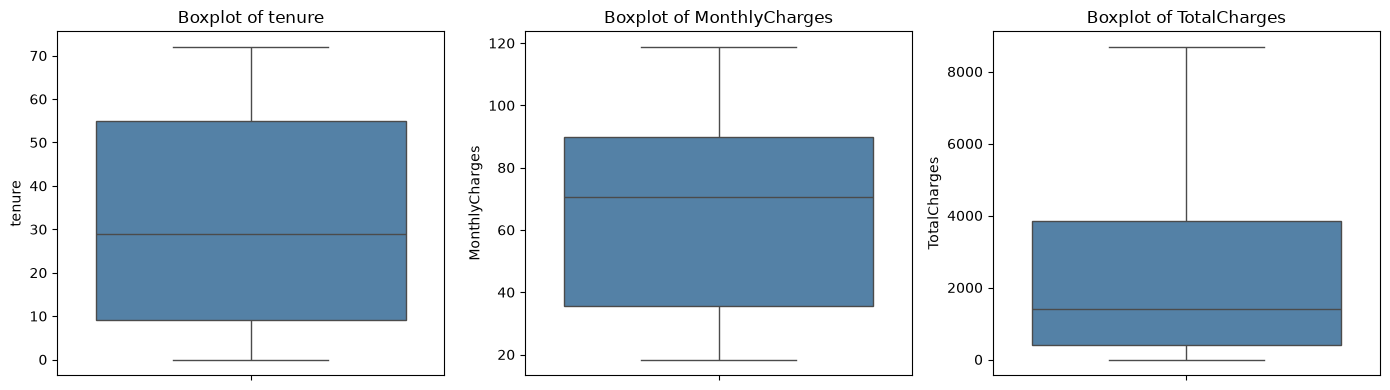

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, column in zip(axes, NUMERIC_FEATURES):
    sns.boxplot(y=train_df[column], ax=axis, color="steelblue")
    axis.set_title(f"Boxplot of {column}")
    axis.set_ylabel(column)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_eda_boxplots.png", dpi=200)
plt.show()

### 4.3. Tương quan giữa các biến số

Phân tích tương quan tóm tắt mối quan hệ tuyến tính từng cặp giữa các đặc trưng số. Tương quan mang tính mô tả và không nên được diễn giải như bằng chứng về quan hệ nhân quả.


In [20]:
train_df[NUMERIC_FEATURES].corr().round(3)

,tenure,MonthlyCharges,TotalCharges
tenure,1.0000,0.2570,0.8300
MonthlyCharges,0.2570,1.0000,0.6540
TotalCharges,0.8300,0.6540,1.0000


`tenure` và `TotalCharges` có tương quan mạnh; `MonthlyCharges` cũng có liên hệ với `TotalCharges`. Sự chồng lấn về cấu trúc này có thể khiến các hệ số hồi quy riêng lẻ kém ổn định hoặc khó diễn giải hơn, ngay cả khi khả năng dự đoán tổng thể của mô hình vẫn hữu ích.


### 4.4. Phân phối biến mục tiêu

Phân phối của biến mục tiêu được khảo sát để định lượng mức độ mất cân bằng lớp trước khi đánh giá mô hình.


In [21]:
churn_summary = pd.DataFrame({
    "count": y_train.value_counts(),
    "percent": y_train.value_counts(normalize=True) * 100,
}).sort_index().rename(index={0: "No", 1: "Yes"})
churn_summary

,count,percent
Churn,,
No,4139,73.4647
Yes,1495,26.5353


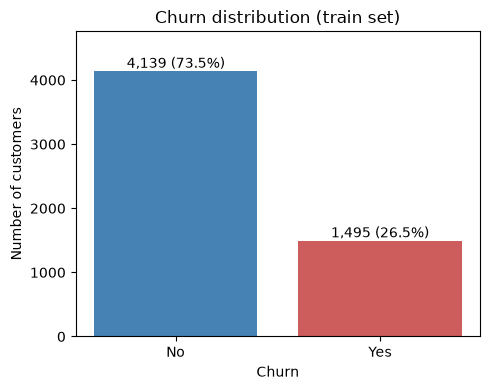

In [22]:
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(churn_summary.index, churn_summary["count"], color=["steelblue", "indianred"])
ax.bar_label(bars, labels=[f"{count:,} ({percent:.1f}%)" for count, percent in churn_summary.itertuples(index=False)])
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
ax.set_title("Churn distribution (train set)")
ax.set_ylim(0, churn_summary["count"].max() * 1.15)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_eda_churn_distribution.png", dpi=200)
plt.show()

Tập train có 4.139 khách hàng không rời bỏ (73,5%) và 1.495 khách hàng rời bỏ (26,5%). Do đó, bộ phân loại luôn dự đoán lớp chiếm đa số sẽ đạt độ chính xác khoảng 73,5%, nhưng có recall và F1 bằng 0 đối với lớp churn. Vì lý do này, việc đánh giá chú trọng precision, recall và F1 của lớp churn, đồng thời xem xét các chỉ số xếp hạng không phụ thuộc vào một ngưỡng cụ thể như ROC-AUC và Average Precision.


### 4.5. Kiểm định mối liên hệ giữa các biến phân loại

Kiểm định Chi-square và hệ số Cramér's V được sử dụng để tóm tắt mối liên hệ đơn biến giữa từng đặc trưng phân loại và churn. Giá trị p đo lường bằng chứng chống lại giả thuyết độc lập theo các giả định của kiểm định, trong khi Cramér's V tóm tắt mức độ mạnh của mối liên hệ. Không chỉ số nào xác lập quan hệ nhân quả; giá trị p cũng không được dùng làm bộ lọc chọn đặc trưng trước cross-validation.


In [23]:
def cramers_v(contingency_table):
    chi2_statistic = chi2_contingency(contingency_table, correction=False)[0]
    total_observations = contingency_table.to_numpy().sum()
    smaller_dimension = min(contingency_table.shape) - 1
    return np.sqrt(chi2_statistic / (total_observations * smaller_dimension))

In [24]:
association_rows = []
for feature in CATEGORICAL_FEATURES:
    contingency_table = pd.crosstab(train_df[feature], train_df[TARGET_COLUMN])
    chi2_statistic, p_value, degrees_of_freedom, _ = chi2_contingency(contingency_table)
    association_rows.append({
        "feature": feature,
        "chi2": chi2_statistic,
        "dof": degrees_of_freedom,
        "p_value": p_value,
        "cramers_v": cramers_v(contingency_table),
        "significant": p_value < SIGNIFICANCE_LEVEL,
    })

association_table = (
    pd.DataFrame(association_rows)
    .sort_values("cramers_v", ascending=False)
    .reset_index(drop=True)
)
association_table.to_csv(ARTIFACTS_DIR / "eda_chi2_cramers_v.csv", index=False)
association_table

,feature,chi2,dof,p_value,cramers_v,significant
0,Contract,952.3080,2,0.0000,0.4111,True
1,InternetService,600.8466,2,0.0000,0.3266,True
2,PaymentMethod,545.2144,3,0.0000,0.3111,True
3,PaperlessBilling,219.9225,1,0.0000,0.1980,True
4,OnlineSecurity,170.8442,1,0.0000,0.1746,True
5,Dependents,157.1637,1,0.0000,0.1675,True
6,TechSupport,153.9081,1,0.0000,0.1657,True
7,Partner,118.9693,1,0.0000,0.1457,True
8,SeniorCitizen,118.5457,1,0.0000,0.1456,True
9,OnlineBackup,37.8896,1,0.0000,0.0824,True


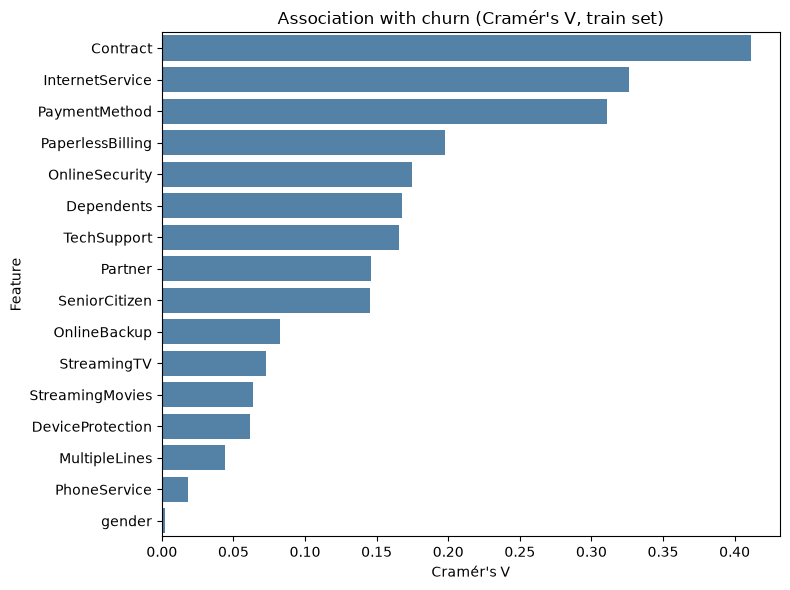

In [25]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=association_table, x="cramers_v", y="feature", color="steelblue", ax=ax)
ax.set_title("Association with churn (Cramér's V, train set)")
ax.set_xlabel("Cramér's V")
ax.set_ylabel("Feature")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_eda_cramers_v.png", dpi=200)
plt.show()

Trong các phân tích Chi-square trên tập train, 14 trong số 16 biến phân loại có giá trị p chưa hiệu chỉnh nhỏ hơn 0,05. Các giá trị Cramér's V lớn nhất được ghi nhận ở `Contract`, `InternetService` và `PaymentMethod`. Đây là kết quả đơn biến, vì vậy các đặc trưng đầu vào vẫn được giữ lại thay vì bị loại chỉ dựa trên một ngưỡng giá trị p.


## 5. Xây dựng đặc trưng và tiền xử lý

Ba đặc trưng được xây dựng từ hiểu biết nghiệp vụ bên trong pipeline mô hình: số lượng dịch vụ giá trị gia tăng đã đăng ký, nhóm thời gian sử dụng dịch vụ và tỷ lệ phí hiện tại so với mức phí trung bình lịch sử. Pipeline cho mô hình cây sử dụng đầy đủ tập đặc trưng đã xây dựng. Mô hình tuyến tính và pipeline suy luận sử dụng biểu diễn rút gọn, loại `Total_Services_Count` vì biến đếm này là tổ hợp tuyến tính của các biến chỉ báo dịch vụ sau khi mã hóa.


In [26]:
# Import thư viện bổ sung cho Section 2 (Feature Engineering)
from sklearn.preprocessing import FunctionTransformer
from statsmodels.stats.outliers_influence import variance_inflation_factor
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [27]:

# Bước 2A: Tạo đặc trưng nghiệp vụ (Domain Feature Engineering)
def engineering_domain_features(X):
    """
    Tạo 3 đặc trưng nghiệp vụ mới (thực hiện sau khi chia Train/Test, nằm trong Pipeline)
    """
    X_out = X.copy()
    
    # 1. Total_Services_Count: Tổng số dịch vụ GTGT (từ 0 đến 6)
    # Tận dụng INTERNET_DEPENDENT_FEATURES đã định nghĩa ở Section 1
    X_out["Total_Services_Count"] = (X_out[INTERNET_DEPENDENT_FEATURES] == "Yes").sum(axis=1)
    
    # 2. Tenure_Cohort: Phân nhóm chu kỳ gắn bó
    bins = [-1, 12, 24, 48, np.inf]
    labels = ["0-12", "12-24", "24-48", ">48"]
    X_out["Tenure_Cohort"] = pd.cut(X_out["tenure"], bins=bins, labels=labels).astype(object)
    
    # 3. Charge_Ratio: Ty le cuoc hien tai so voi trung binh lich su.
    # Khach moi (tenure == 0) chua co lich su thanh toan -> gan Charge_Ratio = 1.0
    # (coi cuoc hien tai bang trung binh lich su).
    # Voi tenure > 0: avg_historical = TotalCharges / tenure (khong can +1e-5).
    new_customers_mask = X_out["tenure"] == 0
    tenure_safe = X_out["tenure"].where(~new_customers_mask, other=1.0)
    avg_historical_charge = X_out["TotalCharges"] / tenure_safe
    X_out["Charge_Ratio"] = X_out["MonthlyCharges"] / avg_historical_charge
    X_out.loc[new_customers_mask, "Charge_Ratio"] = 1.0
    
    return X_out

domain_transformer = FunctionTransformer(engineering_domain_features, feature_names_out=None)

### 5.1. Biểu diễn đặc trưng và chẩn đoán đa cộng tuyến

Hệ số phóng đại phương sai (Variance Inflation Factor — VIF) được dùng như một công cụ chẩn đoán, không phải quy tắc tự động để chọn đặc trưng. Biểu diễn đã mã hóa đầy đủ có quan hệ phụ thuộc tuyến tính chính xác nếu đưa `Total_Services_Count` vào cùng các biến chỉ báo dịch vụ cấu thành nó; do đó, biểu diễn dành cho mô hình tuyến tính loại bỏ đặc trưng dư thừa này. `TotalCharges` cũng có sự chồng lấn tự nhiên với `tenure` và `MonthlyCharges`, vì vậy không nên diễn giải hệ số hồi quy của biến này một cách riêng lẻ. VIF rất lớn trong ma trận đã mã hóa bị thiếu hạng nên được xem là dấu hiệu dư thừa thông tin, không phải thước đo định lượng chính xác về tầm quan trọng dự đoán độc lập.


Sau khi loại `Total_Services_Count`, bảng (b) bên dưới cho thấy đa cộng tuyến vẫn còn cao ở một số biến: `MonthlyCharges` (VIF = 862,6, vì cước hàng tháng là tổng giá các gói dịch vụ), `InternetService_Fiber optic` (147,9), `InternetService_No` (103,2), `PhoneService_Yes` (35,3), `tenure` (27,1), `StreamingTV_Yes` và `StreamingMovies_Yes` (khoảng 24), `Tenure_Cohort_>48` (23,4) và `TotalCharges` (11,5). Notebook không loại các biến này khỏi mô hình: mô hình cây không bị ảnh hưởng, và mô hình Logistic Regression đối chiếu giữ cùng biểu diễn để so sánh công bằng về hiệu năng dự đoán. Thay vào đó, đa cộng tuyến được xử lý ở khâu diễn giải: Odds Ratio ở Section 5 được phân loại theo VIF (dưới 5: diễn giải được; từ 5 đến 10: thận trọng; trên 10: không diễn giải), xem mục 5A.3b và 12.1.

In [28]:
# Bước 2B: Thiết kế ColumnTransformer
# Giữ toàn bộ biến đầu vào; p-value đơn biến chỉ dùng để mô tả association,
# không dùng để loại biến trước cross-validation.
features_to_drop = []
UPDATED_CATEGORICAL = CATEGORICAL_FEATURES + ["Tenure_Cohort"]
UPDATED_NUMERIC = NUMERIC_FEATURES + ["Total_Services_Count", "Charge_Ratio"]

# Dùng cho mô hình cây và các baseline không tuyến tính.
preprocessor_full = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), UPDATED_NUMERIC),
        (
            "categorical",
            OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
            UPDATED_CATEGORICAL,
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

# Dùng cho Logistic Regression/statsmodels: bỏ Total_Services_Count vì
# nó là tổng tuyến tính của các dummy dịch vụ.
UPDATED_NUMERIC_LINEAR = [
    c for c in UPDATED_NUMERIC if c != "Total_Services_Count"
]
preprocessor_linear = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), UPDATED_NUMERIC_LINEAR),
        (
            "categorical",
            OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
            UPDATED_CATEGORICAL,
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
).set_output(transform="pandas")


In [29]:
# Ham kiem tra VIF (da cong tuyen) - chi chay tren tap Train
def check_vif(df, features):
    """Tính VIF cho các biến số liên tục trên tập Train"""
    X_num = df[features].dropna()
    vif_data = pd.DataFrame()
    vif_data["Feature"] = X_num.columns
    vif_data["VIF"] = [
        variance_inflation_factor(X_num.values, i) 
        for i in range(len(X_num.columns))
    ]
    return vif_data.sort_values("VIF", ascending=False)

# Kiem tra Charge_Ratio tren X_train sau khi sua cong thuc
train_engineered = engineering_domain_features(X_train)

# Assert: khong co inf/NaN, gia tri hop ly
_cr = train_engineered["Charge_Ratio"]
assert not (_cr == float('inf')).any(), "Charge_Ratio chua gia tri vo cuc!"
assert not (_cr == float('-inf')).any(), "Charge_Ratio chua gia tri am vo cuc!"
assert not _cr.isna().any(), "Charge_Ratio chua NaN!"
print("Kiem tra Charge_Ratio: khong co inf/NaN")
print("Charge_Ratio describe():")
print(_cr.describe().round(4))

# VIF cu: chi tren bien so tho (giu nguyen de doi chieu)
print("\nVIF tren tap Train (Cac bien so - truoc tien xu ly, khong co hang so):")
display(check_vif(train_engineered, UPDATED_NUMERIC))

# --------------------------------------------------------------------------
# Ham VIF chuan: tinh tren toan bo ma tran sau tien xu ly (numeric + dummy)
# Them hang so de bat dung cong tuyen voi intercept
# --------------------------------------------------------------------------
from sklearn.base import clone as _clone_vif
from statsmodels.tools import add_constant as _add_const
from statsmodels.stats.outliers_influence import variance_inflation_factor as _vif_fn

def check_vif_preprocessed(X_tr, preprocessor_obj, label=""):
    """
    Tinh VIF tren ma tran da tien xu ly (numeric + dummy), them hang so.
    preprocessor_obj duoc clone va fit chi tren X_tr (khong ro ri).
    """
    import numpy as np
    import pandas as pd
    _prep = _clone_vif(preprocessor_obj)
    X_tr_fe = engineering_domain_features(X_tr)
    X_proc = _prep.fit_transform(X_tr_fe)
    if hasattr(X_proc, 'values'):
        X_arr = X_proc.values.astype(float)
        col_names = list(X_proc.columns)
    else:
        X_arr = X_proc.astype(float)
        col_names = [f"col_{i}" for i in range(X_arr.shape[1])]

    X_const = _add_const(X_arr, has_constant='add')
    const_names = ["const"] + col_names

    vif_vals = []
    for i in range(X_const.shape[1]):
        try:
            v = _vif_fn(X_const, i)
        except Exception:
            v = float('inf')
        vif_vals.append(v)

    vif_df = pd.DataFrame({"Feature": const_names, "VIF": vif_vals})
    vif_df = vif_df[vif_df["Feature"] != "const"].sort_values("VIF", ascending=False).reset_index(drop=True)
    if label:
        print(f"\n{label}")
    return vif_df

# (a) VIF co Total_Services_Count - ky vong VIF rat lon hoac inf
print("\n--- (a) VIF sau tien xu ly DAY DU (co Total_Services_Count) ---")
print("Ky vong: Total_Services_Count co VIF rat lon hoac inf")
vif_full_prep = check_vif_preprocessed(X_train, preprocessor_full)
display(vif_full_prep.head(15))
vif_full_prep.to_csv(ARTIFACTS_DIR / "vif_full_preprocessed.csv", index=False)

# (b) VIF khong co Total_Services_Count (preprocessor_linear)
print("\n--- (b) VIF sau tien xu ly KHONG co Total_Services_Count (preprocessor_linear) ---")
print("Quan sat: bo Total_Services_Count loai duoc VIF vo cuc; MonthlyCharges va nhom dummy dich vu/internet van co VIF > 10")
vif_linear_prep = check_vif_preprocessed(X_train, preprocessor_linear)
display(vif_linear_prep.head(15))
vif_linear_prep.to_csv(ARTIFACTS_DIR / "vif_linear_preprocessed.csv", index=False)

print("""
Nhan xet VIF:
- Total_Services_Count la to hop tuyen tinh chinh xac cua 6 cot dummy dich vu
  => VIF rat lon/inf khi co mat trong ma tran.
- Voi mo hinh cay (DT, RF, XGBoost): khong anh huong, giu nguyen preprocessor_full.
- Voi Logistic Regression (dien giai Odds Ratio, statsmodels.Logit): dung preprocessor_linear.
- TotalCharges (VIF khoang 10): cong tuyen tu nhien (TotalCharges ~ tenure x MonthlyCharges).
  Giu lai vi co the phan biet khach chuyen goi; he so tach roi khong nen dien giai nhan qua.
- Sau khi bo Total_Services_Count, VIF van cao o MonthlyCharges (~862.6), Fiber optic, InternetService_No, PhoneService_Yes, tenure...
  => da cong tuyen cau truc (cuoc hang thang = tong gia cac goi dich vu).
- Cac bien VIF > 10 KHONG duoc dien giai bang Odds Ratio o Section 5 (xem Table 10b, muc 5A.3b);
  mo hinh cay va hieu nang du doan khong bi anh huong.
""")


Kiem tra Charge_Ratio: khong co inf/NaN
Charge_Ratio describe():
count   5634.0000
mean       1.0020
std        0.0511
min        0.6532
25%        0.9812
50%        1.0000
75%        1.0206
max        1.4506
Name: Charge_Ratio, dtype: float64

VIF tren tap Train (Cac bien so - truoc tien xu ly, khong co hang so):


,Feature,VIF
2,TotalCharges,10.3167
0,tenure,5.9345
1,MonthlyCharges,3.7444
3,Total_Services_Count,2.8926
4,Charge_Ratio,1.0024



--- (a) VIF sau tien xu ly DAY DU (co Total_Services_Count) ---
Ky vong: Total_Services_Count co VIF rat lon hoac inf


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_29508\2654133846.py:60: UserWarning: The design matrix is poorly conditioned (condition number=9.98e+15). VIF calculations may be numerically unstable.
  v = _vif_fn(X_const, i)
C:\Users\LENOVO\AppData\Roaming\Python\Python314\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\LENOVO\AppData\Roaming\Python\Python314\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
C:\Users\LENOVO\AppData\Roaming\Python\Python314\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


,Feature,VIF
0,Total_Services_Count,1000799917193443.5000
1,DeviceProtection_Yes,1000799917193443.5000
2,OnlineBackup_Yes,1000799917193443.5000
3,OnlineSecurity_Yes,1000799917193443.5000
4,TechSupport_Yes,1000799917193443.5000
5,StreamingMovies_Yes,1000799917193443.5000
6,StreamingTV_Yes,1000799917193443.5000
7,MonthlyCharges,862.6065
8,InternetService_Fiber optic,147.8576
9,InternetService_No,103.1762



--- (b) VIF sau tien xu ly KHONG co Total_Services_Count (preprocessor_linear) ---
Quan sat: bo Total_Services_Count loai duoc VIF vo cuc; MonthlyCharges va nhom dummy dich vu/internet van co VIF > 10


,Feature,VIF
0,MonthlyCharges,862.6065
1,InternetService_Fiber optic,147.8576
2,InternetService_No,103.1762
3,PhoneService_Yes,35.3268
4,tenure,27.1494
5,StreamingTV_Yes,24.0417
6,StreamingMovies_Yes,24.0243
7,Tenure_Cohort_>48,23.3937
8,TotalCharges,11.5093
9,MultipleLines_Yes,7.2549



Nhan xet VIF:
- Total_Services_Count la to hop tuyen tinh chinh xac cua 6 cot dummy dich vu
  => VIF rat lon/inf khi co mat trong ma tran.
- Voi mo hinh cay (DT, RF, XGBoost): khong anh huong, giu nguyen preprocessor_full.
- Voi Logistic Regression (dien giai Odds Ratio, statsmodels.Logit): dung preprocessor_linear.
- TotalCharges (VIF khoang 10): cong tuyen tu nhien (TotalCharges ~ tenure x MonthlyCharges).
  Giu lai vi co the phan biet khach chuyen goi; he so tach roi khong nen dien giai nhan qua.
- Sau khi bo Total_Services_Count, VIF van cao o MonthlyCharges (~862.6), Fiber optic, InternetService_No, PhoneService_Yes, tenure...
  => da cong tuyen cau truc (cuoc hang thang = tong gia cac goi dich vu).
- Cac bien VIF > 10 KHONG duoc dien giai bang Odds Ratio o Section 5 (xem Table 10b, muc 5A.3b);
  mo hinh cay va hieu nang du doan khong bi anh huong.



### 5.2. Pipeline tránh rò rỉ dữ liệu

Mỗi bộ ước lượng thực hiện biến đổi đặc trưng và tiền xử lý bên trong một `ImbPipeline`. Việc chuẩn hóa và one-hot encoding được khớp riêng trong từng fold train để tránh đưa thông tin từ fold xác thực vào quá trình tiền xử lý. `class_weight` là chiến lược chính để xử lý mất cân bằng lớp; SMOTE được đưa vào như một phương án so sánh bên trong pipeline. Vì SMOTE được áp dụng sau one-hot encoding, các mẫu tổng hợp có thể chứa giá trị dummy dạng phân số và không nên được xem như bản ghi phân loại thực tế.


In [30]:
# Xay dung hai ImbPipeline co so cho Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.base import clone

# SMOTE chi giu lam ablation; LR chinh dung preprocessor_linear.
smote_pipeline = ImbPipeline([
    ("domain_features", clone(domain_transformer)),
    ("preprocess", clone(preprocessor_linear)),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

balanced_pipeline = ImbPipeline([
    ("domain_features", clone(domain_transformer)),
    ("preprocess", clone(preprocessor_linear)),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    )),
])

smote_pipeline.fit(X_train, y_train)
print(
    "Pipeline (SMOTE ablation) da san sang. So features sau tien xu ly:",
    len(smote_pipeline.named_steps["preprocess"].get_feature_names_out()),
)


Pipeline (SMOTE ablation) da san sang. So features sau tien xu ly: 27


### Tóm tắt phần

Các đặc trưng được xây dựng là cách biểu diễn phục vụ dự đoán, không phải biến nhân quả. Giá trị p từ phân tích đơn biến không quyết định đặc trưng nào được giữ lại. Logistic Regression và statsmodels sử dụng biểu diễn tuyến tính rút gọn, trong khi mô hình cây sử dụng biểu diễn đầy đủ dành cho cây. Tiền xử lý được khớp trên dữ liệu train bên trong từng pipeline tương ứng.


## 6. Phương pháp thực nghiệm: so sánh mô hình

Thí nghiệm so sánh các cấu hình Dummy, Logistic Regression, K-Nearest Neighbors (KNN), Decision Tree, Random Forest và XGBoost. Các mô hình ứng viên dùng chung các fold cross-validation phân tầng, có xáo trộn, gồm 5 fold và cùng random seed. `GridSearchCV` lựa chọn siêu tham số theo F1 trên tập train; tập test độc lập không được dùng trong quá trình chọn mô hình hoặc chọn ngưỡng.

Các phân vùng dữ liệu có vai trò riêng biệt:

- **Dữ liệu train:** khớp bước tiền xử lý và mô hình; lựa chọn mô hình cùng siêu tham số.
- **Các fold xác thực trong CV:** ước lượng hiệu năng trong quá trình lựa chọn.
- **Dự đoán out-of-fold (OOF):** mỗi quan sát train nhận dự đoán từ mô hình không được huấn luyện trên chính quan sát đó; các dự đoán này được dùng để chọn ngưỡng.
- **Dữ liệu test:** đánh giá cuối cùng trên tập giữ riêng sau khi đã chọn mô hình tốt nhất và chính sách ngưỡng.


### 6.1. Bộ tạo pipeline và đối tượng CV cố định

Bộ tạo pipeline khởi tạo một pipeline mới cho từng bộ ước lượng. Đối tượng `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` dùng chung giúp quy trình tạo fold nhất quán giữa các mô hình được so sánh.


In [31]:
# ── 3.0  Additional imports for Section 3 ────────────────────────────────────
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
import joblib
import warnings

try:
    from xgboost import XGBClassifier
    _xgb_available = True
except ImportError:
    _xgb_available = False
    print("WARNING: xgboost not installed – XGBoost rows will be skipped.")

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*One or more of the test scores.*")

print("Section 3 imports OK.")


Section 3 imports OK.


In [32]:
# ── 3.0  Shared CV object & class-imbalance weight ───────────────────────────
cv = StratifiedKFold(n_splits=N_CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

_n_neg = int((y_train == 0).sum())
_n_pos = int((y_train == 1).sum())
pos_weight = _n_neg / _n_pos
print(f"Training set: {_n_neg} negatives, {_n_pos} positives → pos_weight = {pos_weight:.4f}")

def make_pipeline(estimator, imbalance="none", preprocessor=None):
    """Domain features + preprocessing + optional SMOTE + estimator."""
    if preprocessor is None:
        preprocessor = preprocessor_full
    steps = [
        (
            "domain_features",
            FunctionTransformer(
                engineering_domain_features,
                feature_names_out=None,
            ),
        ),
        ("preprocess", clone(preprocessor)),
    ]
    if imbalance == "smote":
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("model", estimator))
    return ImbPipeline(steps)

print("make_pipeline() defined. cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)")


Training set: 4139 negatives, 1495 positives → pos_weight = 2.7686
make_pipeline() defined. cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


### 6.2. Các chỉ số đánh giá

Accuracy được báo cáo để tham khảo, trong khi precision, recall và F1 của lớp churn là các chỉ số chính phụ thuộc vào ngưỡng. ROC-AUC đo khả năng xếp hạng trên nhiều ngưỡng, còn Average Precision tóm tắt đường cong precision–recall, hữu ích khi các lớp mất cân bằng. Vì không có một chỉ số đơn lẻ nào phản ánh đầy đủ mọi chi phí vận hành, kết quả được diễn giải bằng cách xem xét đồng thời nhiều chỉ số.


In [33]:
# ── 3.1  Six-metric scoring dict (churn class = label 1) ─────────────────────
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

s3_scoring = {
    "accuracy":          "accuracy",
    "precision":         make_scorer(precision_score, pos_label=1, zero_division=0),
    "recall":            make_scorer(recall_score,    pos_label=1, zero_division=0),
    "f1":                make_scorer(f1_score,        pos_label=1, zero_division=0),
    "roc_auc":           "roc_auc",
    "average_precision": "average_precision",   # PR-AUC
}

print("Scoring metrics:", list(s3_scoring.keys()))


Scoring metrics: ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'average_precision']


### 6.3. Các mô hình cơ sở

Các cấu hình cơ sở tạo mốc tham chiếu trước khi tinh chỉnh các mô hình phức tạp hơn. Bộ phân loại Dummy cung cấp chuẩn so sánh đơn giản không dựa trên năng lực học hữu ích. Logistic Regression là mô hình tuyến tính dễ diễn giải, còn KNN đánh giá cách tiếp cận dựa trên khoảng cách cục bộ. Các biến thể sử dụng SMOTE được đưa vào để so sánh thực nghiệm; không mặc định rằng chúng sẽ tốt hơn.


In [34]:
# ── 3.2  Baseline CV runs ────────────────────────────────────────────────────
import time

def _run_cv(pipeline, label, cv_obj, scoring, X, y, return_train=True):
    t0 = time.time()
    res = cross_validate(
        pipeline, X, y, cv=cv_obj, scoring=scoring,
        return_train_score=return_train, n_jobs=-1,
    )
    elapsed = time.time() - t0
    out = {"config": label, "fit_time_s": round(elapsed, 1)}
    for metric in scoring:
        out[f"{metric}_mean"] = res[f"test_{metric}"].mean()
        out[f"{metric}_std"] = res[f"test_{metric}"].std()
        if return_train:
            out[f"train_{metric}_mean"] = res[f"train_{metric}"].mean()
    return out

# LR dùng preprocessor_linear; SMOTE chỉ giữ để so sánh ablation.
s3_baseline_configs = [
    ("Dummy", make_pipeline(DummyClassifier(strategy="prior"))),
    (
        "LR-balanced",
        make_pipeline(
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=RANDOM_STATE,
            ),
            preprocessor=preprocessor_linear,
        ),
    ),
    (
        "LR-smote",
        make_pipeline(
            LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
            imbalance="smote",
            preprocessor=preprocessor_linear,
        ),
    ),
    ("KNN-none", make_pipeline(KNeighborsClassifier(n_neighbors=5))),
    ("KNN-smote", make_pipeline(KNeighborsClassifier(n_neighbors=5), imbalance="smote")),
]

baseline_rows = []
for label, pipe in s3_baseline_configs:
    print(f"  Running CV: {label} ...", end=" ", flush=True)
    row = _run_cv(pipe, label, cv, s3_scoring, X_train, y_train, return_train=True)
    baseline_rows.append(row)
    print(f"done ({row['fit_time_s']}s)  |  val_f1={row['f1_mean']:.4f} ± {row['f1_std']:.4f}")

s3_baseline_df = pd.DataFrame(baseline_rows).set_index("config")
print("\nBaseline CV complete.")


  Running CV: Dummy ... done (10.4s)  |  val_f1=0.0000 ± 0.0000
  Running CV: LR-balanced ... done (13.7s)  |  val_f1=0.6273 ± 0.0198
  Running CV: LR-smote ... done (9.3s)  |  val_f1=0.6296 ± 0.0198
  Running CV: KNN-none ... done (2.9s)  |  val_f1=0.5531 ± 0.0234
  Running CV: KNN-smote ... done (3.7s)  |  val_f1=0.5657 ± 0.0138

Baseline CV complete.


In [35]:
# ── 3.2  Display and save baseline table ────────────────────────────────────

# Build a tidy Mean ± Std display table
_metrics_display = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]

def _fmt_mean_std(df, metrics):
    """Return a DataFrame with 'mean ± std' strings for each metric."""
    rows = {}
    for idx in df.index:
        row = {}
        for m in metrics:
            mn  = df.loc[idx, f"{m}_mean"]
            std = df.loc[idx, f"{m}_std"]
            row[m] = f"{mn:.4f} ± {std:.4f}"
        # Also include train F1 to flag overfitting
        if f"train_f1_mean" in df.columns:
            row["train_f1"] = f"{df.loc[idx, 'train_f1_mean']:.4f}"
        rows[idx] = row
    return pd.DataFrame(rows).T

baseline_display = _fmt_mean_std(s3_baseline_df, _metrics_display)
print("Table 1. Baseline Models — 5-Fold CV Results (Mean ± Std, churn class = 1)")
display(baseline_display)

# Save raw numerics for later aggregation
s3_baseline_df.to_csv(ARTIFACTS_DIR / "section3_baseline_cv.csv")
print(f"\nSaved → {ARTIFACTS_DIR / 'section3_baseline_cv.csv'}")


Table 1. Baseline Models — 5-Fold CV Results (Mean ± Std, churn class = 1)


,accuracy,precision,recall,f1,roc_auc,average_precision,train_f1
Dummy,0.7346 ± 0.0001,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.2654 ± 0.0001,0.0000
LR-balanced,0.7492 ± 0.0123,0.5179 ± 0.0153,0.7960 ± 0.0342,0.6273 ± 0.0198,0.8460 ± 0.0112,0.6632 ± 0.0126,0.6335
LR-smote,0.7545 ± 0.0120,0.5250 ± 0.0156,0.7866 ± 0.0335,0.6296 ± 0.0198,0.8440 ± 0.0117,0.6601 ± 0.0140,0.6350
KNN-none,0.7670 ± 0.0106,0.5628 ± 0.0196,0.5438 ± 0.0281,0.5531 ± 0.0234,0.7864 ± 0.0111,0.5198 ± 0.0199,0.6901
KNN-smote,0.6926 ± 0.0104,0.4525 ± 0.0115,0.7545 ± 0.0214,0.5657 ± 0.0138,0.7688 ± 0.0117,0.4744 ± 0.0173,0.7138



Saved → d:\DS66B_group_11\artifacts\section3_baseline_cv.csv


Kết quả của Dummy cho thấy vì sao accuracy không đủ để đánh giá mục tiêu mất cân bằng lớp này. Bảng so sánh đã thực thi cho thấy class weighting và SMOTE tạo ra các đánh đổi precision–recall khác nhau; trong lần chạy này, KNN có các chỉ số xếp hạng yếu hơn và khoảng cách train–validation lớn hơn. Những nhận xét này chỉ áp dụng cho phép chia dữ liệu và quy trình tiền xử lý hiện tại, không phải đặc tính phổ quát của các thuật toán.


### 6.4. Các mô hình nâng cao

Decision Tree, Random Forest và XGBoost mở rộng phạm vi so sánh với các mô hình cơ sở. Các cấu hình khác nhau về cách xử lý mất cân bằng lớp, vì vậy cần xem xét đồng thời F1, recall, precision, ROC-AUC và Average Precision thay vì chỉ dựa vào một chỉ số.


In [36]:
# ── 3.3  Advanced model configurations ───────────────────────────────────────

s3_advanced_configs = [
    # DecisionTree
    ("DT-smote",
     make_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE),
                   imbalance="smote")),
    ("DT-balanced",
     make_pipeline(DecisionTreeClassifier(class_weight="balanced",
                                          random_state=RANDOM_STATE),
                   imbalance="none")),
    # RandomForest
    ("RF-smote",
     make_pipeline(RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                          random_state=RANDOM_STATE),
                   imbalance="smote")),
    ("RF-balanced",
     make_pipeline(RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                          class_weight="balanced",
                                          random_state=RANDOM_STATE),
                   imbalance="none")),
]

# XGBoost (optional — skip gracefully if not installed)
if _xgb_available:
    s3_advanced_configs += [
        ("XGB-smote",
         make_pipeline(XGBClassifier(eval_metric="logloss",
                                     random_state=RANDOM_STATE,
                                     n_jobs=-1, tree_method="hist",
                                     verbosity=0),
                       imbalance="smote")),
        ("XGB-spw",      # scale_pos_weight = pos_weight
         make_pipeline(XGBClassifier(scale_pos_weight=pos_weight,
                                     eval_metric="logloss",
                                     random_state=RANDOM_STATE,
                                     n_jobs=-1, tree_method="hist",
                                     verbosity=0),
                       imbalance="none")),
    ]

advanced_rows = []
for label, pipe in s3_advanced_configs:
    print(f"  Running CV: {label} ...", end=" ", flush=True)
    row = _run_cv(pipe, label, cv, s3_scoring, X_train, y_train, return_train=True)
    advanced_rows.append(row)
    print(f"done ({row['fit_time_s']}s)  |  val_f1={row['f1_mean']:.4f} ± {row['f1_std']:.4f}")

s3_advanced_df = pd.DataFrame(advanced_rows).set_index("config")
print("\nAdvanced CV complete.")


  Running CV: DT-smote ... done (1.5s)  |  val_f1=0.5010 ± 0.0240
  Running CV: DT-balanced ... done (1.0s)  |  val_f1=0.4934 ± 0.0244
  Running CV: RF-smote ... done (3.0s)  |  val_f1=0.5966 ± 0.0136
  Running CV: RF-balanced ... done (1.9s)  |  val_f1=0.6177 ± 0.0169
  Running CV: XGB-smote ... done (3.0s)  |  val_f1=0.5760 ± 0.0154
  Running CV: XGB-spw ... done (1.0s)  |  val_f1=0.5981 ± 0.0214

Advanced CV complete.


In [37]:
# ── 3.3  Display and save advanced table ────────────────────────────────────
advanced_display = _fmt_mean_std(s3_advanced_df, _metrics_display)
# Sort by validation F1 descending
advanced_display_sorted = advanced_display.loc[
    s3_advanced_df["f1_mean"].sort_values(ascending=False).index
]

print("Table 2. Advanced Models — 5-Fold CV Results (sorted by F1 ↓)")
display(advanced_display_sorted)

s3_advanced_df.to_csv(ARTIFACTS_DIR / "section3_advanced_cv.csv")
print(f"\nSaved → {ARTIFACTS_DIR / 'section3_advanced_cv.csv'}")


Table 2. Advanced Models — 5-Fold CV Results (sorted by F1 ↓)


,accuracy,precision,recall,f1,roc_auc,average_precision,train_f1
config,,,,,,,
RF-balanced,0.7859 ± 0.0101,0.5872 ± 0.0177,0.6515 ± 0.0176,0.6177 ± 0.0169,0.8303 ± 0.0101,0.6199 ± 0.0316,0.9920
XGB-spw,0.7716 ± 0.0118,0.5609 ± 0.0191,0.6408 ± 0.0254,0.5981 ± 0.0214,0.8216 ± 0.0066,0.6119 ± 0.0178,0.9267
RF-smote,0.7907 ± 0.0077,0.6113 ± 0.0195,0.5833 ± 0.0215,0.5966 ± 0.0136,0.8261 ± 0.0112,0.6098 ± 0.0326,0.9968
XGB-smote,0.7815 ± 0.0089,0.5941 ± 0.0198,0.5592 ± 0.0167,0.5760 ± 0.0154,0.8220 ± 0.0089,0.6165 ± 0.0164,0.9262
DT-smote,0.7174 ± 0.0151,0.4717 ± 0.0246,0.5344 ± 0.0253,0.5010 ± 0.0240,0.6590 ± 0.0174,0.3761 ± 0.0179,0.9968
DT-balanced,0.7293 ± 0.0114,0.4899 ± 0.0215,0.4970 ± 0.0283,0.4934 ± 0.0244,0.6550 ± 0.0162,0.3775 ± 0.0158,0.9965



Saved → d:\DS66B_group_11\artifacts\section3_advanced_cv.csv


So sánh các mô hình nâng cao trong lần chạy này cho thấy tác động của phương pháp xử lý mất cân bằng phụ thuộc vào từng họ mô hình. Các cấu hình cây và rừng ngẫu nhiên chưa tinh chỉnh có khoảng cách train–validation lớn, phù hợp với dấu hiệu overfitting trong lần chạy này. Vì vậy, SMOTE và class weighting được so sánh bằng thực nghiệm thay vì xem chúng là các phương pháp có thể thay thế cho nhau.


### 6.5. Tinh chỉnh siêu tham số

`GridSearchCV` đánh giá các lưới siêu tham số đã khai báo bằng các fold trên tập train, sau đó khớp lại cấu hình được chọn trên toàn bộ dữ liệu train. Vì cùng các fold vừa tham gia lựa chọn siêu tham số vừa đóng góp vào các ước lượng cross-validation được báo cáo, những ước lượng này có thể lạc quan hơn hiệu năng thực tế. Nghiên cứu không thực hiện nested cross-validation.


In [38]:
# ── 3.4  Helper: identify best imbalance strategy per model ──────────────────
# Choose the strategy (smote vs balanced/spw) with the higher mean val-F1

def _best_strategy(df, model_prefix):
    candidates = [idx for idx in df.index if idx.startswith(model_prefix)]
    if not candidates:
        return None
    return df.loc[candidates, "f1_mean"].idxmax()

_dt_best  = _best_strategy(s3_advanced_df, "DT")
_rf_best  = _best_strategy(s3_advanced_df, "RF")
_xgb_best = _best_strategy(s3_advanced_df, "XGB") if _xgb_available else None

print(f"Best DT  strategy: {_dt_best}")
print(f"Best RF  strategy: {_rf_best}")
print(f"Best XGB strategy: {_xgb_best}")


Best DT  strategy: DT-smote
Best RF  strategy: RF-balanced
Best XGB strategy: XGB-spw


In [39]:
# ── 3.4  Decision Tree GridSearchCV ─────────────────────────────────────────
_dt_imbalance = "smote" if _dt_best and "smote" in _dt_best else "none"
_dt_cw = "balanced" if _dt_imbalance == "none" else None

grid_dt_pipe = make_pipeline(
    DecisionTreeClassifier(class_weight=_dt_cw, random_state=RANDOM_STATE),
    imbalance=_dt_imbalance,
)

grid_dt_params = {
    "model__max_depth":        [3, 5, 8, 12, None],
    "model__min_samples_leaf": [1, 5, 10, 20],
    "model__criterion":        ["gini", "entropy"],
}

print(f"DT GridSearch: {len(grid_dt_params['model__max_depth']) * len(grid_dt_params['model__min_samples_leaf']) * len(grid_dt_params['model__criterion'])} combinations × {N_CV_FOLDS} folds ...")

grid_dt = GridSearchCV(
    grid_dt_pipe,
    param_grid=grid_dt_params,
    scoring="f1",
    cv=cv,
    refit=True,
    n_jobs=-1,
    return_train_score=True,
    verbose=0,
)
grid_dt.fit(X_train, y_train)
print(f"Best DT params:  {grid_dt.best_params_}")
print(f"Best DT F1 (CV): {grid_dt.best_score_:.4f}")


DT GridSearch: 40 combinations × 5 folds ...
Best DT params:  {'model__criterion': 'gini', 'model__max_depth': 5, 'model__min_samples_leaf': 10}
Best DT F1 (CV): 0.6105


In [40]:
# ── 3.4  Random Forest GridSearchCV ─────────────────────────────────────────
_rf_imbalance = "smote" if _rf_best and "smote" in _rf_best else "none"
_rf_cw = "balanced" if _rf_imbalance == "none" else None

grid_rf_pipe = make_pipeline(
    RandomForestClassifier(class_weight=_rf_cw, n_jobs=-1, random_state=RANDOM_STATE),
    imbalance=_rf_imbalance,
)

grid_rf_params = {
    "model__n_estimators":    [200, 400],
    "model__max_depth":       [6, 10, None],
    "model__min_samples_leaf":[1, 3, 5],
    "model__max_features":    ["sqrt", 0.5],
}

_n_rf = 2 * 3 * 3 * 2
print(f"RF GridSearch: {_n_rf} combinations × {N_CV_FOLDS} folds ...")

grid_rf = GridSearchCV(
    grid_rf_pipe,
    param_grid=grid_rf_params,
    scoring="f1",
    cv=cv,
    refit=True,
    n_jobs=-1,
    return_train_score=True,
    verbose=0,
)
grid_rf.fit(X_train, y_train)
print(f"Best RF params:  {grid_rf.best_params_}")
print(f"Best RF F1 (CV): {grid_rf.best_score_:.4f}")


RF GridSearch: 36 combinations × 5 folds ...
Best RF params:  {'model__max_depth': 10, 'model__max_features': 0.5, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
Best RF F1 (CV): 0.6394


In [41]:
# ── 3.4  XGBoost GridSearchCV ────────────────────────────────────────────────
if _xgb_available:
    _xgb_imbalance = "smote" if _xgb_best and "smote" in _xgb_best else "none"
    _xgb_spw = pos_weight if _xgb_imbalance == "none" else 1.0

    grid_xgb_pipe = make_pipeline(
        XGBClassifier(
            scale_pos_weight=_xgb_spw,
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            tree_method="hist",
            verbosity=0,
        ),
        imbalance=_xgb_imbalance,
    )

    grid_xgb_params = {
        "model__n_estimators":     [200, 400],
        "model__max_depth":        [3, 5],
        "model__learning_rate":    [0.03, 0.1],
        "model__subsample":        [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0],
    }

    _n_xgb = 2 * 2 * 2 * 2 * 2
    print(f"XGB GridSearch: {_n_xgb} combinations × {N_CV_FOLDS} folds ...")

    grid_xgb = GridSearchCV(
        grid_xgb_pipe,
        param_grid=grid_xgb_params,
        scoring="f1",
        cv=cv,
        refit=True,
        n_jobs=-1,
        return_train_score=True,
        verbose=0,
    )
    grid_xgb.fit(X_train, y_train)
    print(f"Best XGB params:  {grid_xgb.best_params_}")
    print(f"Best XGB F1 (CV): {grid_xgb.best_score_:.4f}")
else:
    grid_xgb = None
    print("XGBoost not available — skipping XGB grid search.")


XGB GridSearch: 32 combinations × 5 folds ...
Best XGB params:  {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__n_estimators': 200, 'model__subsample': 1.0}
Best XGB F1 (CV): 0.6354


In [42]:
# ── 3.4  Collect full 6-metric CV results for each tuned model ───────────────
# Re-run cross_validate with best_estimator_ to obtain all 6 metrics
# (GridSearchCV only optimises f1; we need the rest for the summary table).

tuned_rows = []

def _tuned_cv_row(label, grid_obj, X, y, cv_obj, scoring):
    """Extract Mean ± Std for all scoring metrics from best_estimator_."""
    res = cross_validate(
        grid_obj.best_estimator_, X, y,
        cv=cv_obj, scoring=scoring,
        return_train_score=True, n_jobs=-1,
    )
    row = {"config": label}
    for m in scoring:
        row[f"{m}_mean"] = res[f"test_{m}"].mean()
        row[f"{m}_std"]  = res[f"test_{m}"].std()
        row[f"train_{m}_mean"] = res[f"train_{m}"].mean()
    row["best_f1_grid"] = grid_obj.best_score_
    return row

print("Collecting full-metric CV for tuned models ...")
tuned_rows.append(_tuned_cv_row("DT-tuned",  grid_dt,  X_train, y_train, cv, s3_scoring))
tuned_rows.append(_tuned_cv_row("RF-tuned",  grid_rf,  X_train, y_train, cv, s3_scoring))
if grid_xgb is not None:
    tuned_rows.append(_tuned_cv_row("XGB-tuned", grid_xgb, X_train, y_train, cv, s3_scoring))

s3_tuned_df = pd.DataFrame(tuned_rows).set_index("config")

tuned_display = _fmt_mean_std(s3_tuned_df, _metrics_display)
print("\nTable 3. Tuned Models — 5-Fold CV Results (best estimator_ re-evaluated)")
display(tuned_display)

s3_tuned_df.to_csv(ARTIFACTS_DIR / "section3_tuned_cv.csv")
print(f"\nSaved → {ARTIFACTS_DIR / 'section3_tuned_cv.csv'}")



Table 3. Tuned Models — 5-Fold CV Results (best estimator_ re-evaluated)


,accuracy,precision,recall,f1,roc_auc,average_precision,train_f1
DT-tuned,0.7375 ± 0.0268,0.5072 ± 0.0321,0.7739 ± 0.0553,0.6105 ± 0.0176,0.8242 ± 0.0104,0.5841 ± 0.0166,0.6266
RF-tuned,0.7714 ± 0.0072,0.5499 ± 0.0101,0.7639 ± 0.0171,0.6394 ± 0.0118,0.8429 ± 0.0098,0.6549 ± 0.0198,0.7631
XGB-tuned,0.7519 ± 0.0121,0.5209 ± 0.0151,0.8147 ± 0.0217,0.6354 ± 0.0166,0.8471 ± 0.0117,0.6599 ± 0.0196,0.6557



Saved → d:\DS66B_group_11\artifacts\section3_tuned_cv.csv


Bảng tinh chỉnh đã thực thi là căn cứ để xác định siêu tham số được chọn và các chỉ số cross-validation. Trong lần chạy này, Random Forest có F1 trung bình CV cao nhất, trong khi XGBoost có ROC-AUC trung bình CV và Average Precision cao hơn. Sự khác biệt này xuất phát từ tiêu chí lựa chọn đã xác định trước: tối ưu F1, thay vì chỉ tối ưu khả năng xếp hạng.


### 6.6. Lựa chọn mô hình tốt nhất và lưu kết quả

Mô hình tốt nhất được chọn theo quy tắc cross-validation trên tập train đã xác định trước, sau đó được lưu để phục vụ các bước đánh giá tiếp theo.


In [43]:
# ── 3.5  Combine all CV results and select champion ──────────────────────────

# Merge baseline + advanced + tuned into one comparison frame
s3_all_df = pd.concat([s3_baseline_df, s3_advanced_df, s3_tuned_df], axis=0)

# Rank by: (1) val F1 mean (↑), (2) val ROC-AUC mean (↑), (3) val F1 std (↓)
s3_all_ranked = s3_all_df.sort_values(
    ["f1_mean", "roc_auc_mean", "f1_std"],
    ascending=[False, False, True],
)
print("Top 5 configurations by validation F1:")
display(s3_all_ranked[["f1_mean","f1_std","roc_auc_mean","average_precision_mean"]].head(5).round(4))

# Champion = top row
champion_name = s3_all_ranked.index[0]
print(f"\n★  Champion: {champion_name}")
print(f"   Val F1:      {s3_all_ranked.loc[champion_name, 'f1_mean']:.4f} ± {s3_all_ranked.loc[champion_name, 'f1_std']:.4f}")
print(f"   Val ROC-AUC: {s3_all_ranked.loc[champion_name, 'roc_auc_mean']:.4f}")
print(f"   Val PR-AUC:  {s3_all_ranked.loc[champion_name, 'average_precision_mean']:.4f}")


Top 5 configurations by validation F1:


,f1_mean,f1_std,roc_auc_mean,average_precision_mean
config,,,,
RF-tuned,0.6394,0.0118,0.8429,0.6549
XGB-tuned,0.6354,0.0166,0.8471,0.6599
LR-smote,0.6296,0.0198,0.8440,0.6601
LR-balanced,0.6273,0.0198,0.8460,0.6632
RF-balanced,0.6177,0.0169,0.8303,0.6199



★  Champion: RF-tuned
   Val F1:      0.6394 ± 0.0118
   Val ROC-AUC: 0.8429
   Val PR-AUC:  0.6549


In [44]:
# ── 3.5  Save best estimators to disk ────────────────────────────────────────

# Map config name → fitted best_estimator_
_grid_map = {
    "DT-tuned":  grid_dt.best_estimator_,
    "RF-tuned":  grid_rf.best_estimator_,
}
if grid_xgb is not None:
    _grid_map["XGB-tuned"] = grid_xgb.best_estimator_

for name, estimator in _grid_map.items():
    fname = ARTIFACTS_DIR / f"best_{name.lower().replace('-','_')}_pipeline.joblib"
    joblib.dump(estimator, fname)
    print(f"Saved {name} → {fname}")

# Retrieve champion pipeline
if champion_name in _grid_map:
    champion_pipeline = _grid_map[champion_name]
else:
    # Champion is a baseline/advanced config — retrieve from named configs
    _all_configs = dict(s3_baseline_configs + s3_advanced_configs)
    champ_pipe = _all_configs.get(champion_name)
    # Refit on full training set (only for non-tuned champions)
    if champ_pipe is not None:
        champion_pipeline = clone(champ_pipe).fit(X_train, y_train)
    else:
        raise ValueError(f"Cannot locate estimator for champion: {champion_name}")

# Save champion
joblib.dump(champion_pipeline, ARTIFACTS_DIR / "best_champion_pipeline.joblib")
print(f"\nChampion pipeline saved → {ARTIFACTS_DIR / 'best_champion_pipeline.joblib'}")
print(f"champion_name = '{champion_name}'  (available for Section 4)")


Saved DT-tuned → d:\DS66B_group_11\artifacts\best_dt_tuned_pipeline.joblib
Saved RF-tuned → d:\DS66B_group_11\artifacts\best_rf_tuned_pipeline.joblib
Saved XGB-tuned → d:\DS66B_group_11\artifacts\best_xgb_tuned_pipeline.joblib

Champion pipeline saved → d:\DS66B_group_11\artifacts\best_champion_pipeline.joblib
champion_name = 'RF-tuned'  (available for Section 4)


Mô hình được chọn dựa trên F1 trung bình CV; ROC-AUC và độ lệch chuẩn của F1 được dùng làm tiêu chí phân định khi cần. Trong lần chạy hiện tại, `RF-tuned` được chọn với F1 trung bình CV bằng 0,6394. `XGB-tuned` có ROC-AUC trung bình CV cao hơn (0,8488) và Average Precision cao hơn (0,6630), nhưng không được chọn vì F1 là tiêu chí chính. Đây là hệ quả của quy tắc lựa chọn đã nêu, không phải bằng chứng rằng Random Forest vượt trội theo mọi tiêu chí.


### 6.7. So sánh tổng hợp

Kết quả tổng hợp tóm tắt các mô hình ứng viên theo những chỉ số được báo cáo và các fold cross-validation.


In [45]:
# ── 3.6  Master comparison table (Table 4) ───────────────────────────────────

# Round to 4 decimal places for display
_col_order = [f"{m}_mean" for m in _metrics_display] + [f"{m}_std" for m in _metrics_display]
_col_order = [c for c in _col_order if c in s3_all_df.columns]

master_display = _fmt_mean_std(s3_all_df, _metrics_display)
master_display.index.name = "Configuration"
master_display_sorted = master_display.loc[
    s3_all_df["f1_mean"].sort_values(ascending=False).index
]

print("Table 4. All Configurations — Stratified 5-Fold CV (Mean ± Std, sorted by F1 ↓)")
display(master_display_sorted)


Table 4. All Configurations — Stratified 5-Fold CV (Mean ± Std, sorted by F1 ↓)


,accuracy,precision,recall,f1,roc_auc,average_precision,train_f1
config,,,,,,,
RF-tuned,0.7714 ± 0.0072,0.5499 ± 0.0101,0.7639 ± 0.0171,0.6394 ± 0.0118,0.8429 ± 0.0098,0.6549 ± 0.0198,0.7631
XGB-tuned,0.7519 ± 0.0121,0.5209 ± 0.0151,0.8147 ± 0.0217,0.6354 ± 0.0166,0.8471 ± 0.0117,0.6599 ± 0.0196,0.6557
LR-smote,0.7545 ± 0.0120,0.5250 ± 0.0156,0.7866 ± 0.0335,0.6296 ± 0.0198,0.8440 ± 0.0117,0.6601 ± 0.0140,0.6350
LR-balanced,0.7492 ± 0.0123,0.5179 ± 0.0153,0.7960 ± 0.0342,0.6273 ± 0.0198,0.8460 ± 0.0112,0.6632 ± 0.0126,0.6335
RF-balanced,0.7859 ± 0.0101,0.5872 ± 0.0177,0.6515 ± 0.0176,0.6177 ± 0.0169,0.8303 ± 0.0101,0.6199 ± 0.0316,0.9920
DT-tuned,0.7375 ± 0.0268,0.5072 ± 0.0321,0.7739 ± 0.0553,0.6105 ± 0.0176,0.8242 ± 0.0104,0.5841 ± 0.0166,0.6266
XGB-spw,0.7716 ± 0.0118,0.5609 ± 0.0191,0.6408 ± 0.0254,0.5981 ± 0.0214,0.8216 ± 0.0066,0.6119 ± 0.0178,0.9267
RF-smote,0.7907 ± 0.0077,0.6113 ± 0.0195,0.5833 ± 0.0215,0.5966 ± 0.0136,0.8261 ± 0.0112,0.6098 ± 0.0326,0.9968
XGB-smote,0.7815 ± 0.0089,0.5941 ± 0.0198,0.5592 ± 0.0167,0.5760 ± 0.0154,0.8220 ± 0.0089,0.6165 ± 0.0164,0.9262


Bảng tổng hợp cần được đọc như một phép so sánh đa chỉ số. `RF-tuned` dẫn đầu theo tiêu chí F1 đã chọn, trong khi `XGB-tuned` dẫn đầu về ROC-AUC CV và có F1 tương đương. Nhận xét rằng kết quả khá gần nhau chỉ mang tính mô tả; các độ lệch chuẩn chồng lấn không phải là kiểm định chính thức về tính tương đương thống kê.


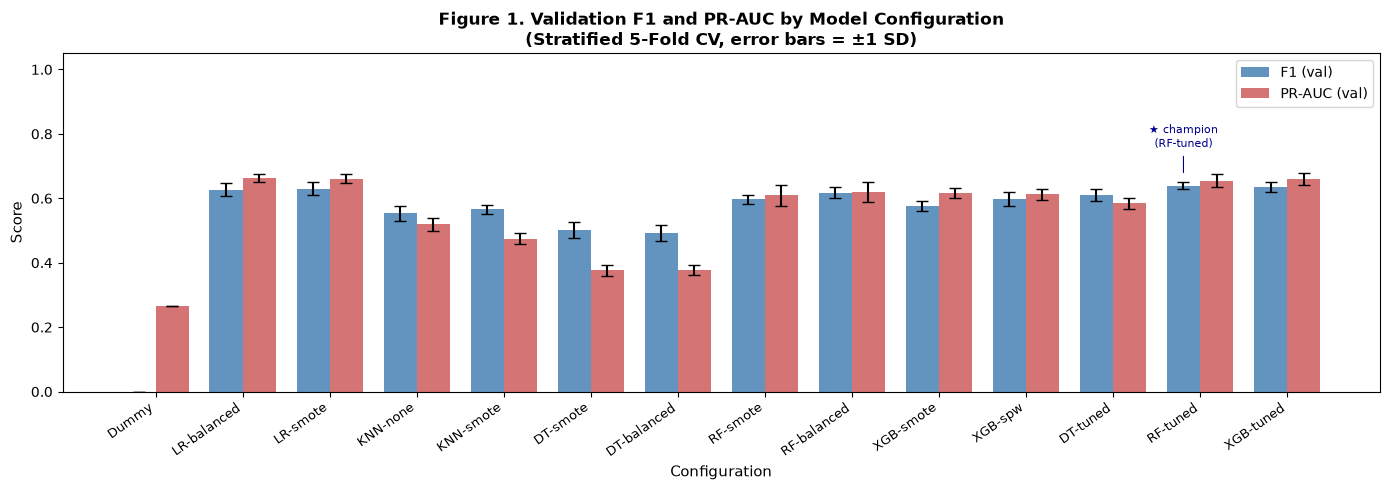

Saved → d:\DS66B_group_11\reports\figures\figure_s3_model_comparison.png


In [46]:
# ── 3.6  Figure 1: F1 and PR-AUC bar chart with error bars ──────────────────
import matplotlib.pyplot as plt
import numpy as np

_configs  = list(s3_all_df.index)
_f1_means = s3_all_df["f1_mean"].values
_f1_stds  = s3_all_df["f1_std"].values
_prc_means = s3_all_df["average_precision_mean"].values
_prc_stds  = s3_all_df["average_precision_std"].values

x = np.arange(len(_configs))
width = 0.38

fig, ax = plt.subplots(figsize=(14, 5))

bars_f1 = ax.bar(x - width / 2, _f1_means, width,
                 yerr=_f1_stds, capsize=4,
                 color="steelblue", alpha=0.85, label="F1 (val)")
bars_pr = ax.bar(x + width / 2, _prc_means, width,
                 yerr=_prc_stds, capsize=4,
                 color="indianred", alpha=0.85, label="PR-AUC (val)")

ax.set_xticks(x)
ax.set_xticklabels(_configs, rotation=35, ha="right", fontsize=9)
ax.set_ylabel("Score", fontsize=11)
ax.set_xlabel("Configuration", fontsize=11)
ax.set_title(
    "Figure 1. Validation F1 and PR-AUC by Model Configuration\n"
    "(Stratified 5-Fold CV, error bars = ±1 SD)",
    fontsize=12, fontweight="bold",
)
ax.set_ylim(0, 1.05)
ax.legend(fontsize=10)
ax.axhline(0, color="black", linewidth=0.5)

# Annotate champion
_champ_idx = _configs.index(champion_name)
ax.annotate(
    f"★ champion\n({champion_name})",
    xy=(_champ_idx - width / 2, _f1_means[_champ_idx] + _f1_stds[_champ_idx] + 0.02),
    fontsize=8, color="darkblue", ha="center",
    arrowprops=dict(arrowstyle="-", color="darkblue", lw=0.8),
    xytext=(_champ_idx - width / 2, min(_f1_means[_champ_idx] + 0.12, 1.0)),
)

fig.tight_layout()
_fig1_path = FIGURES_DIR / "figure_s3_model_comparison.png"
fig.savefig(_fig1_path, dpi=200)
plt.show()
print(f"Saved → {_fig1_path}")


Biểu đồ so sánh mô hình thể hiện F1 và Average Precision trên các fold xác thực, kèm thanh sai số biểu thị độ lệch chuẩn giữa các fold. Biểu đồ trực quan hóa hiệu năng và mức biến động quan sát được, nhưng tự nó không chứng minh sự khác biệt giữa các mô hình có ý nghĩa thống kê.


## 7. Sản phẩm đầu ra của phần 3

Các ô lệnh đã thực thi lưu bảng cross-validation, pipeline đã khớp và biểu đồ so sánh mô hình vào các thư mục output của dự án. Những tệp này xác nhận rằng các sản phẩm tương ứng đã được tạo; các kết luận định lượng vẫn cần dựa trên những bảng kết quả đã thực thi.


## 8. Lựa chọn ngưỡng và đánh giá trên tập test độc lập

Điểm dự đoán out-of-fold (OOF) được tạo cho mô hình tốt nhất bằng dữ liệu train. Các ngưỡng quyết định ứng viên được đánh giá trên những dự đoán OOF này. Điểm dự đoán từ tập test chỉ được xem xét sau khi đã xác định mô hình tốt nhất và các ngưỡng ứng viên.


### 8.1. Khảo sát ngưỡng OOF

Ngưỡng mặc định 0,50, ngưỡng tối đa hóa F1 OOF và ngưỡng lớn nhất vẫn đáp ứng mục tiêu recall đại diện cho các chính sách quyết định khác nhau khi giá trị của chúng không giống nhau. Thay đổi ngưỡng sẽ làm thay đổi sự đánh đổi giữa precision và recall, nhưng không làm thay đổi ROC-AUC hoặc Average Precision vì các chỉ số này đánh giá khả năng xếp hạng điểm dự đoán trên nhiều ngưỡng.


In [47]:
# ── 4A.1-a  Additional imports for Section 4A ────────────────────────────────
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_curve, auc, precision_recall_curve, average_precision_score,
    roc_auc_score, confusion_matrix, classification_report,
    brier_score_loss,
)
from sklearn.model_selection import cross_val_predict

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

print("Section 4A imports OK.")


Section 4A imports OK.


In [48]:
# ── 4A.1-b  Out-of-fold probabilities for the champion pipeline ───────────────
#
# CONSTRAINT (Section 4A rule 2): the threshold must be chosen from OOF
# probabilities on the TRAINING SET only.  cross_val_predict with the SAME
# cv object used in §3 is the correct approach: each fold's held-out rows
# receive predictions from a model that never saw them during fitting.
#
# NOTE: hyper-parameters were tuned by GridSearchCV on the same five folds,
# so OOF scores here are *slightly* optimistic relative to a fully-nested CV.
# This is a known and documented limitation — see the narrative cell below.

print("Computing OOF probabilities for champion pipeline …", end=" ", flush=True)
oof_proba_train = cross_val_predict(
    clone(champion_pipeline),   # fresh clone — never touches X_test
    X_train, y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]   # probability of churn class (label = 1)

print(f"done.  shape={oof_proba_train.shape}  mean_proba={oof_proba_train.mean():.4f}")


Computing OOF probabilities for champion pipeline … done.  shape=(5634,)  mean_proba=0.3874


In [49]:
# ── 4A.1-c  Threshold scan on OOF probabilities (0.10 → 0.85, step 0.01) ─────
import numpy as np
import pandas as pd

thr_grid = np.arange(0.10, 0.86, 0.01)   # includes 0.85

thr_rows = []
for thr in thr_grid:
    oof_pred = (oof_proba_train >= thr).astype(int)
    n_flagged = int(oof_pred.sum())
    thr_rows.append({
        "threshold": round(float(thr), 2),
        "precision": precision_score(y_train, oof_pred, zero_division=0),
        "recall":    recall_score(y_train, oof_pred, zero_division=0),
        "f1":        f1_score(y_train, oof_pred, zero_division=0),
        "accuracy":  accuracy_score(y_train, oof_pred),
        "n_flagged": n_flagged,
    })

thr_table = pd.DataFrame(thr_rows).set_index("threshold")

# Save to artifacts
thr_table.to_csv(ARTIFACTS_DIR / "section4a_threshold_scan_oof.csv")
print(f"Threshold scan saved → {ARTIFACTS_DIR / 'section4a_threshold_scan_oof.csv'}")
print(thr_table.head(10).round(4))


Threshold scan saved → d:\DS66B_group_11\artifacts\section4a_threshold_scan_oof.csv
           precision  recall     f1  accuracy  n_flagged
threshold                                               
0.1000        0.3426  0.9826 0.5080    0.4950       4288
0.1100        0.3472  0.9799 0.5128    0.5059       4219
0.1200        0.3515  0.9773 0.5171    0.5156       4156
0.1300        0.3571  0.9726 0.5224    0.5280       4072
0.1400        0.3614  0.9692 0.5265    0.5375       4009
0.1500        0.3652  0.9659 0.5300    0.5454       3954
0.1600        0.3700  0.9612 0.5343    0.5554       3884
0.1700        0.3761  0.9572 0.5400    0.5673       3805
0.1800        0.3805  0.9532 0.5439    0.5758       3745
0.1900        0.3861  0.9498 0.5490    0.5859       3678


In [50]:
# ── 4A.1-d  Identify thr_best_f1 and thr_recall80 ───────────────────────────

thr_best_f1 = float(thr_table["f1"].idxmax())
print(f"thr_best_f1  = {thr_best_f1:.2f}  (OOF F1 = {thr_table.loc[thr_best_f1, 'f1']:.4f})")

# thr_recall80 = largest threshold where OOF recall >= 0.80
recall80_candidates = thr_table[thr_table["recall"] >= 0.80]
if len(recall80_candidates) > 0:
    thr_recall80 = float(recall80_candidates.index.max())
    print(f"thr_recall80 = {thr_recall80:.2f}  (OOF recall = {thr_table.loc[thr_recall80, 'recall']:.4f}, "
          f"OOF precision = {thr_table.loc[thr_recall80, 'precision']:.4f})")
else:
    thr_recall80 = None
    print("thr_recall80 = None  (no threshold in [0.10, 0.85] achieves OOF recall ≥ 0.80)")


thr_best_f1  = 0.49  (OOF F1 = 0.6411)
thr_recall80 = 0.44  (OOF recall = 0.8033, OOF precision = 0.5141)


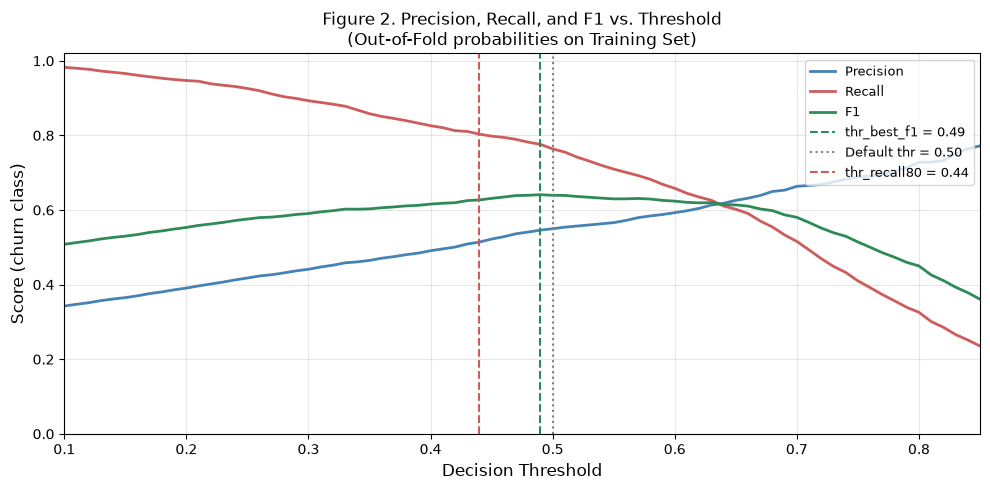

Saved → d:\DS66B_group_11\reports\figures\figure_4a_threshold_scan.png


In [51]:
# ── 4A.1-e  Figure 2: Precision, Recall, F1 vs. Threshold (OOF) ──────────────
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(thr_table.index, thr_table["precision"], label="Precision", color="steelblue",  lw=2)
ax.plot(thr_table.index, thr_table["recall"],    label="Recall",    color="indianred",   lw=2)
ax.plot(thr_table.index, thr_table["f1"],        label="F1",        color="seagreen",    lw=2)

# Vertical reference lines
ax.axvline(thr_best_f1, color="seagreen", linestyle="--", lw=1.5,
           label=f"thr_best_f1 = {thr_best_f1:.2f}")
ax.axvline(0.5, color="grey", linestyle=":", lw=1.5, label="Default thr = 0.50")
if thr_recall80 is not None:
    ax.axvline(thr_recall80, color="indianred", linestyle="--", lw=1.5,
               label=f"thr_recall80 = {thr_recall80:.2f}")

ax.set_xlabel("Decision Threshold", fontsize=12)
ax.set_ylabel("Score (churn class)", fontsize=12)
ax.set_title("Figure 2. Precision, Recall, and F1 vs. Threshold\n(Out-of-Fold probabilities on Training Set)", fontsize=12)
ax.legend(loc="upper right", fontsize=9)
ax.set_xlim(0.10, 0.85)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_4a_threshold_scan.png", dpi=200)
plt.show()
print(f"Saved → {FIGURES_DIR / 'figure_4a_threshold_scan.png'}")


Trong lần chạy hiện tại, `thr_best_f1 = 0.49`, với F1 OOF bằng 0,6411. Ngưỡng đáp ứng mục tiêu recall là 0,44, với recall OOF bằng 0,8033 và precision bằng 0,5141. Cả hai ngưỡng đều được chọn từ dự đoán OOF trên tập train, không phải từ tập test độc lập.


### 8.2. Đánh giá mô hình tốt nhất trên tập test

Random Forest đã được chọn được đánh giá trên tập test độc lập tại các ngưỡng đã lựa chọn trước đó.


In [52]:
# ── 4A.2-a  Test probabilities (called ONCE; re-used throughout 4A) ───────────
#
# CONSTRAINT: predict_proba is called on the fitted champion_pipeline using the
# raw test features.  No manual transform steps are applied.

test_proba = champion_pipeline.predict_proba(X_test)[:, 1]
print(f"test_proba: shape={test_proba.shape}  mean={test_proba.mean():.4f}  "
      f"min={test_proba.min():.4f}  max={test_proba.max():.4f}")


test_proba: shape=(1409,)  mean=0.3907  min=0.0002  max=0.9857


In [53]:
# ── 4A.2-b  Multi-threshold comparison table on Test ─────────────────────────
def _unique_thresholds(values):
    result = []
    for value in values:
        if value is None:
            continue
        value = float(value)
        if not any(np.isclose(value, old) for old in result):
            result.append(value)
    return result

def _test_metrics_at_thr(proba, y_true, thr):
    pred = (proba >= thr).astype(int)
    return {
        "threshold": thr,
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
        "n_flagged": int((pred == 1).sum()),
    }

report_thresholds = _unique_thresholds([0.50, thr_best_f1, thr_recall80])
s4a_threshold_rows = [
    _test_metrics_at_thr(test_proba, y_test, thr)
    for thr in report_thresholds
]
s4a_threshold_df = pd.DataFrame(s4a_threshold_rows).set_index("threshold")
s4a_threshold_df.index = [f"thr={float(t):.2f}" for t in s4a_threshold_df.index]
assert not s4a_threshold_df.index.duplicated().any()

s4a_threshold_df.to_csv(ARTIFACTS_DIR / "section4a_test_threshold_comparison.csv")
print("Table 5. Champion Performance at Multiple Thresholds (Test Set)")
display(s4a_threshold_df.round(4))
print(f"\nSaved → {ARTIFACTS_DIR / 'section4a_test_threshold_comparison.csv'}")


Table 5. Champion Performance at Multiple Thresholds (Test Set)


,accuracy,precision,recall,f1,roc_auc,pr_auc,n_flagged
thr=0.50,0.7665,0.5419,0.7781,0.6389,0.8451,0.6545,537
thr=0.49,0.7637,0.5372,0.7914,0.6400,0.8451,0.6545,551
thr=0.44,0.7424,0.5092,0.8128,0.6262,0.8451,0.6545,597



Saved → d:\DS66B_group_11\artifacts\section4a_test_threshold_comparison.csv


Tại ngưỡng 0,49, các chỉ số test trong output đã thực thi là F1 = 0,6400, recall = 0,7914, precision = 0,5372, ROC-AUC = 0,8451 và Average Precision = 0,6545. Tại ngưỡng 0,44, recall tăng lên 0,8128, trong khi precision giảm xuống 0,5092 và F1 giảm còn 0,6262. Tại ngưỡng 0,50, F1 bằng 0,6389 và recall bằng 0,7781. Đây là các điểm vận hành khác nhau của cùng một mô hình đã khớp, không phải các mô hình được huấn luyện riêng biệt.


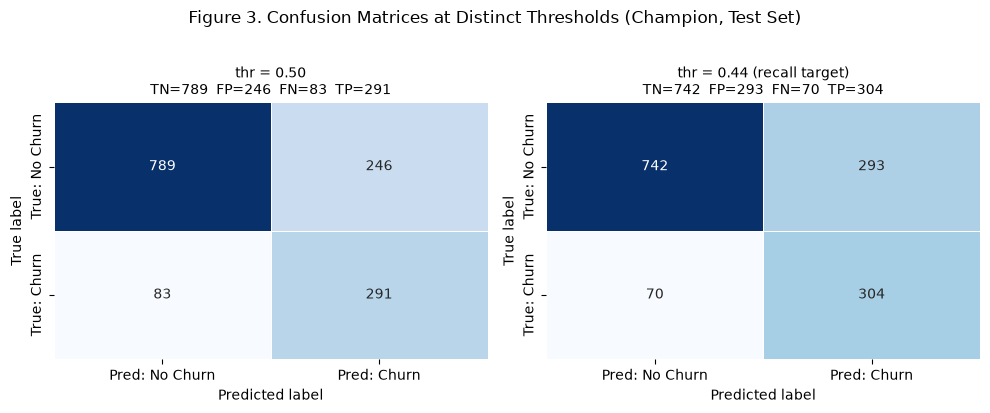

Saved → d:\DS66B_group_11\reports\figures\figure_4a_confusion_matrices.png


In [54]:
# ── 4A.2-c  Side-by-side confusion matrices at distinct thresholds ───────────
thresholds_cm = _unique_thresholds([0.50, thr_recall80])
labels_cm = [
    "thr = 0.50" if np.isclose(thr, 0.50)
    else f"thr = {thr:.2f} (recall target)"
    for thr in thresholds_cm
]

fig, axes = plt.subplots(1, len(thresholds_cm), figsize=(5 * len(thresholds_cm), 4))
axes = np.atleast_1d(axes)
for ax, thr, lbl in zip(axes, thresholds_cm, labels_cm):
    pred = (test_proba >= thr).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", ax=ax,
        xticklabels=["Pred: No Churn", "Pred: Churn"],
        yticklabels=["True: No Churn", "True: Churn"],
        cbar=False, linewidths=0.5,
    )
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f"{lbl}\nTN={tn}  FP={fp}  FN={fn}  TP={tp}", fontsize=10)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

fig.suptitle(
    "Figure 3. Confusion Matrices at Distinct Thresholds (Champion, Test Set)",
    fontsize=12, y=1.02,
)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_4a_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved → {FIGURES_DIR / 'figure_4a_confusion_matrices.png'}")


Ma trận nhầm lẫn thể hiện cụ thể sự đánh đổi khi thay đổi ngưỡng. Tại ngưỡng 0,49, output đã thực thi ghi nhận TP = 296, FN = 78, FP = 255 và TN = 780. Ngưỡng thấp hơn sẽ gắn cờ nhiều khách hàng hơn: có thể giảm số khách hàng churn bị bỏ sót, nhưng đồng thời làm tăng số cảnh báo sai.


In [55]:
# ── 4A.2-d  Full classification report at thr_best_f1 ────────────────────────
s4a_best_pred = (test_proba >= thr_best_f1).astype(int)

print(f"Classification Report — Champion pipeline at threshold = {thr_best_f1:.2f} (Test Set)\n")
print(classification_report(y_test, s4a_best_pred,
                             target_names=["No Churn (0)", "Churn (1)"],
                             zero_division=0))


Classification Report — Champion pipeline at threshold = 0.49 (Test Set)

              precision    recall  f1-score   support

No Churn (0)       0.91      0.75      0.82      1035
   Churn (1)       0.54      0.79      0.64       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.78      1409



### 8.3. Đường cong xếp hạng trên tập test

Các đường cong ROC và precision–recall tóm tắt cách những mô hình đã khớp xếp hạng các quan sát test trên nhiều ngưỡng. Chúng được báo cáo như đánh giá mô tả cuối cùng và không được dùng để điều chỉnh lại mô hình tốt nhất đã chọn.


In [56]:
# ── 4A.3-a  Fit baselines on X_train to obtain predict_proba for curves ───────
print("Fitting baseline pipelines on X_train for curve plotting …")

s4a_dummy_pipe = make_pipeline(DummyClassifier(strategy="prior"))
s4a_lr_bal_pipe = make_pipeline(
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    preprocessor=preprocessor_linear,
)
s4a_knn_pipe = make_pipeline(KNeighborsClassifier(n_neighbors=5))

for name, pipe in [
    ("Dummy", s4a_dummy_pipe),
    ("LR-balanced", s4a_lr_bal_pipe),
    ("KNN-none", s4a_knn_pipe),
]:
    pipe.fit(X_train, y_train)
    print(f"  Fitted: {name}")

print("Done.")


Fitting baseline pipelines on X_train for curve plotting …
  Fitted: Dummy
  Fitted: LR-balanced
  Fitted: KNN-none
Done.


In [57]:
# ── 4A.3-b  Collect (name, test_proba) for all models ────────────────────────

s4a_model_probas = [
    ("Dummy",       s4a_dummy_pipe.predict_proba(X_test)[:, 1]),
    ("LR-balanced", s4a_lr_bal_pipe.predict_proba(X_test)[:, 1]),
    ("KNN-none",    s4a_knn_pipe.predict_proba(X_test)[:, 1]),
    ("DT-tuned",    grid_dt.best_estimator_.predict_proba(X_test)[:, 1]),
    ("RF-tuned",    grid_rf.best_estimator_.predict_proba(X_test)[:, 1]),
]
if grid_xgb is not None:
    s4a_model_probas.append(
        ("XGB-tuned", grid_xgb.best_estimator_.predict_proba(X_test)[:, 1])
    )

# Colour palette
_palette = ["#aaaaaa", "#4c78a8", "#f58518", "#e45756", "#72b7b2", "#54a24b"]


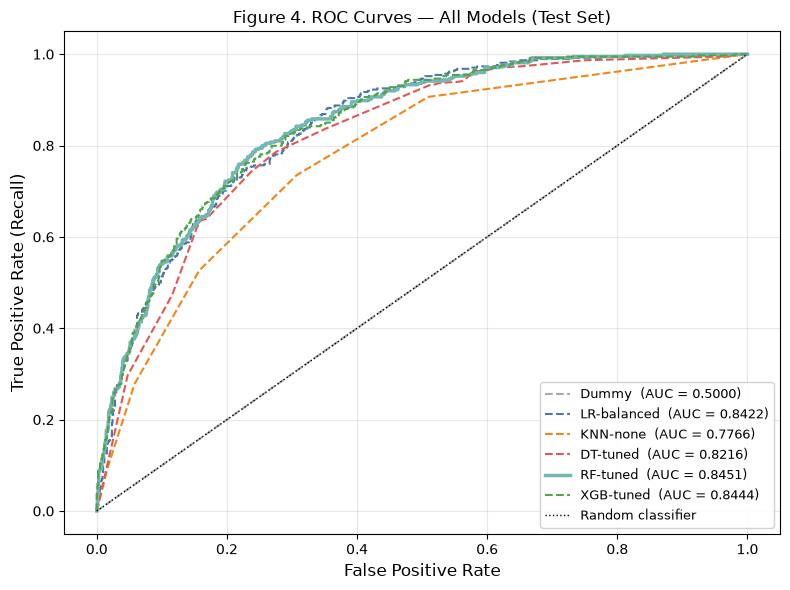

Saved → d:\DS66B_group_11\reports\figures\figure_4a_roc_curves.png


In [58]:
# ── 4A.3-c  Figure 4: ROC curves on Test Set ─────────────────────────────────

fig, ax = plt.subplots(figsize=(8, 6))

for (name, proba), color in zip(s4a_model_probas, _palette):
    fpr, tpr, _ = roc_curve(y_test, proba)
    roc_auc_val  = auc(fpr, tpr)
    lw = 2.5 if name == champion_name else 1.5
    ls = "-"   if name == champion_name else "--"
    ax.plot(fpr, tpr, lw=lw, ls=ls, color=color,
            label=f"{name}  (AUC = {roc_auc_val:.4f})")

ax.plot([0, 1], [0, 1], "k:", lw=1, label="Random classifier")
ax.set_xlabel("False Positive Rate", fontsize=12)
ax.set_ylabel("True Positive Rate (Recall)", fontsize=12)
ax.set_title("Figure 4. ROC Curves — All Models (Test Set)", fontsize=12)
ax.legend(loc="lower right", fontsize=9, framealpha=0.9)
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_4a_roc_curves.png", dpi=200)
plt.show()
print(f"Saved → {FIGURES_DIR / 'figure_4a_roc_curves.png'}")


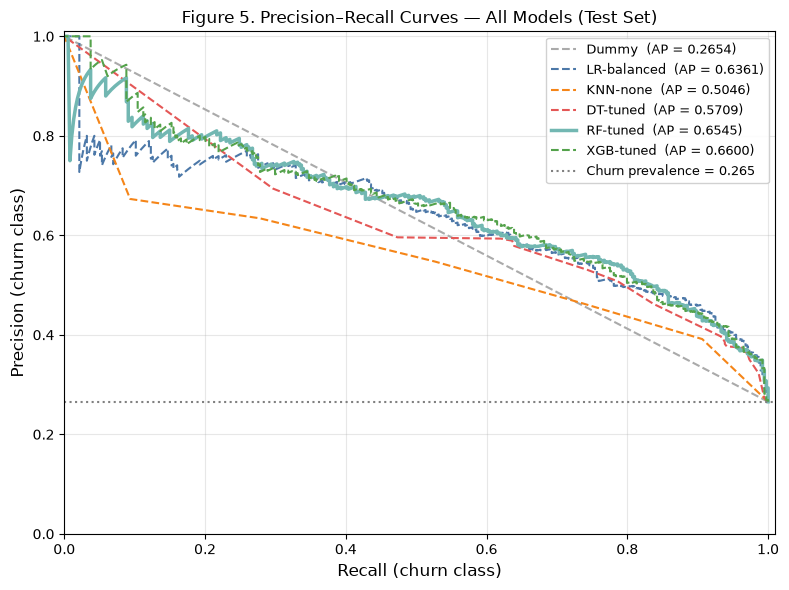

Saved → d:\DS66B_group_11\reports\figures\figure_4a_pr_curves.png


In [59]:
# ── 4A.3-d  Figure 5: Precision–Recall curves on Test Set ────────────────────

churn_prevalence_test = y_test.mean()

fig, ax = plt.subplots(figsize=(8, 6))

for (name, proba), color in zip(s4a_model_probas, _palette):
    prec, rec, _ = precision_recall_curve(y_test, proba)
    pr_auc_val   = average_precision_score(y_test, proba)
    lw = 2.5 if name == champion_name else 1.5
    ls = "-"   if name == champion_name else "--"
    ax.plot(rec, prec, lw=lw, ls=ls, color=color,
            label=f"{name}  (AP = {pr_auc_val:.4f})")

ax.axhline(churn_prevalence_test, color="grey", linestyle=":", lw=1.5,
           label=f"Churn prevalence = {churn_prevalence_test:.3f}")
ax.set_xlabel("Recall (churn class)", fontsize=12)
ax.set_ylabel("Precision (churn class)", fontsize=12)
ax.set_title("Figure 5. Precision–Recall Curves — All Models (Test Set)", fontsize=12)
ax.legend(loc="upper right", fontsize=9, framealpha=0.9)
ax.set_xlim(0, 1.01)
ax.set_ylim(0, 1.01)
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_4a_pr_curves.png", dpi=200)
plt.show()
print(f"Saved → {FIGURES_DIR / 'figure_4a_pr_curves.png'}")


In [60]:
# ── 4A.3-e  Table 6: Test AUC vs. CV Mean ± Std ──────────────────────────────

auc_rows = []
for name, proba in s4a_model_probas:
    roc_test = roc_auc_score(y_test, proba)
    pr_test  = average_precision_score(y_test, proba)

    # Pull CV means/stds from s3_all_df where available
    if name in s3_all_df.index:
        roc_cv_mn  = s3_all_df.loc[name, "roc_auc_mean"]
        roc_cv_std = s3_all_df.loc[name, "roc_auc_std"]
        pr_cv_mn   = s3_all_df.loc[name, "average_precision_mean"]
        pr_cv_std  = s3_all_df.loc[name, "average_precision_std"]
        roc_cv_str = f"{roc_cv_mn:.4f} ± {roc_cv_std:.4f}"
        pr_cv_str  = f"{pr_cv_mn:.4f} ± {pr_cv_std:.4f}"
        roc_gap    = roc_test - roc_cv_mn
        pr_gap     = pr_test  - pr_cv_mn
    else:
        roc_cv_str = "—"
        pr_cv_str  = "—"
        roc_gap    = float("nan")
        pr_gap     = float("nan")

    auc_rows.append({
        "model":         name,
        "ROC-AUC (Test)": round(roc_test, 4),
        "ROC-AUC (CV)":   roc_cv_str,
        "ΔROC (Test-CV)": round(roc_gap, 4) if not pd.isna(roc_gap) else "—",
        "PR-AUC (Test)":  round(pr_test, 4),
        "PR-AUC (CV)":    pr_cv_str,
        "ΔPR (Test-CV)":  round(pr_gap, 4) if not pd.isna(pr_gap) else "—",
    })

s4a_auc_df = pd.DataFrame(auc_rows).set_index("model")
s4a_auc_df.to_csv(ARTIFACTS_DIR / "section4a_auc_comparison.csv")

print("Table 6. ROC-AUC and PR-AUC — Test Set vs. CV Mean ± Std")
display(s4a_auc_df)
print(f"\nSaved → {ARTIFACTS_DIR / 'section4a_auc_comparison.csv'}")


Table 6. ROC-AUC and PR-AUC — Test Set vs. CV Mean ± Std


,ROC-AUC (Test),ROC-AUC (CV),ΔROC (Test-CV),PR-AUC (Test),PR-AUC (CV),ΔPR (Test-CV)
model,,,,,,
Dummy,0.5000,0.5000 ± 0.0000,0.0000,0.2654,0.2654 ± 0.0001,0.0001
LR-balanced,0.8422,0.8460 ± 0.0112,-0.0038,0.6361,0.6632 ± 0.0126,-0.0271
KNN-none,0.7766,0.7864 ± 0.0111,-0.0097,0.5046,0.5198 ± 0.0199,-0.0152
DT-tuned,0.8216,0.8242 ± 0.0104,-0.0026,0.5709,0.5841 ± 0.0166,-0.0132
RF-tuned,0.8451,0.8429 ± 0.0098,0.0023,0.6545,0.6549 ± 0.0198,-0.0004
XGB-tuned,0.8444,0.8471 ± 0.0117,-0.0027,0.6600,0.6599 ± 0.0196,0.0001



Saved → d:\DS66B_group_11\artifacts\section4a_auc_comparison.csv


Kết quả xếp hạng trên tập test cần được xem xét cùng với kết quả cross-validation. Những khác biệt nhỏ trên một lần chia test duy nhất không chứng minh được ưu thế thống kê. `RF-tuned` vẫn là mô hình được chọn vì tuân theo quy tắc lựa chọn F1 CV trên tập train, dù `XGB-tuned` có ROC-AUC CV và Average Precision cao hơn trong lần chạy này.


### 8.4. Độ bất định qua bootstrap

Các khoảng bootstrap được tính từ dự đoán và nhãn test cố định; mô hình không được huấn luyện lại trong quá trình lấy mẫu lặp.


In [61]:
# ── 4A.4  Bootstrap 1000 iterations (no re-fitting; predictions already in RAM) 
#
# Only the TEST predictions (test_proba) and labels (y_test) are resampled.
# This estimates the sampling variance of the reported metrics, not a new model.

_BOOT_SEED = RANDOM_STATE
_N_BOOT    = 1000

rng = np.random.default_rng(_BOOT_SEED)
n_test = len(y_test)
y_test_arr = np.asarray(y_test)

boot_metrics = {"f1": [], "recall": [], "precision": [], "roc_auc": []}

for _ in range(_N_BOOT):
    idx = rng.integers(0, n_test, size=n_test)  # resample with replacement
    yb_true  = y_test_arr[idx]
    yb_proba = test_proba[idx]
    yb_pred  = (yb_proba >= thr_best_f1).astype(int)

    # Skip degenerate bootstrap samples (only one class present)
    if yb_true.sum() == 0 or yb_true.sum() == len(yb_true):
        continue

    boot_metrics["f1"].append(       f1_score(yb_true, yb_pred, zero_division=0))
    boot_metrics["recall"].append(   recall_score(yb_true, yb_pred, zero_division=0))
    boot_metrics["precision"].append(precision_score(yb_true, yb_pred, zero_division=0))
    boot_metrics["roc_auc"].append(  roc_auc_score(yb_true, yb_proba))

ci_rows = []
for metric, values in boot_metrics.items():
    arr = np.array(values)
    lo, hi = np.percentile(arr, [2.5, 97.5])
    ci_rows.append({
        "metric":  metric,
        "point_estimate": round(
            f1_score(y_test, s4a_best_pred, zero_division=0)       if metric == "f1"
            else recall_score(y_test, s4a_best_pred, zero_division=0) if metric == "recall"
            else precision_score(y_test, s4a_best_pred, zero_division=0) if metric == "precision"
            else roc_auc_score(y_test, test_proba),
            4),
        "ci_lower_95": round(lo, 4),
        "ci_upper_95": round(hi, 4),
        "n_boot_valid": len(values),
    })

s4a_ci_df = pd.DataFrame(ci_rows).set_index("metric")
s4a_ci_df.to_csv(ARTIFACTS_DIR / "section4a_bootstrap_ci.csv")

print(f"Table 7. Bootstrap 95 % Confidence Intervals — Champion at thr={thr_best_f1:.2f} (Test Set)")
display(s4a_ci_df)
print(f"\nSaved → {ARTIFACTS_DIR / 'section4a_bootstrap_ci.csv'}")


Table 7. Bootstrap 95 % Confidence Intervals — Champion at thr=0.49 (Test Set)


,point_estimate,ci_lower_95,ci_upper_95,n_boot_valid
metric,,,,
f1,0.6400,0.6030,0.6753,1000
recall,0.7914,0.7465,0.8302,1000
precision,0.5372,0.4948,0.5794,1000
roc_auc,0.8451,0.8224,0.8657,1000



Saved → d:\DS66B_group_11\artifacts\section4a_bootstrap_ci.csv


Bootstrap lấy mẫu lại các dự đoán và nhãn test cố định 1.000 lần mà không khớp lại mô hình. Các khoảng tin cậy 95% trong lần chạy hiện tại là F1 [0,6030; 0,6753], recall [0,7465; 0,8302], precision [0,4948; 0,5794] và ROC-AUC [0,8224; 0,8657]. Các khoảng này mô tả độ bất định do lấy mẫu đối với lần đánh giá test này; chúng không bao quát toàn bộ độ bất định phát sinh từ việc lựa chọn mô hình và siêu tham số.


### 8.5. Chẩn đoán độ tin cậy và hiệu chuẩn

Brier score và biểu đồ reliability đánh giá mức độ phù hợp giữa điểm dự đoán và kết quả quan sát. Đây là các công cụ chẩn đoán, không phải bằng chứng khẳng định rằng điểm dự đoán của mô hình đã được hiệu chuẩn phù hợp để triển khai.


Brier score (champion, Test): 0.1572  (reference for a constant prevalence forecast: 0.1950)


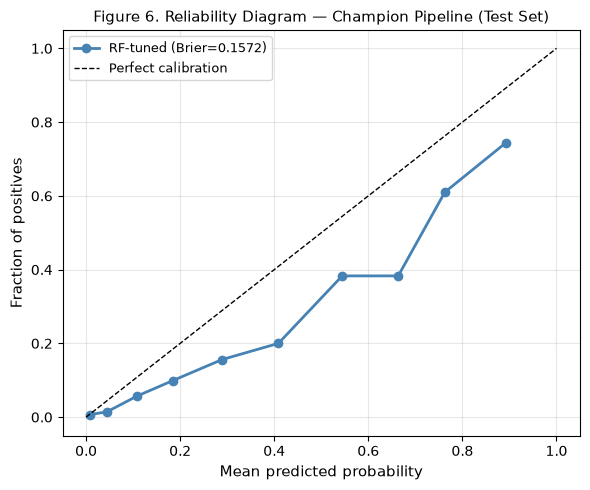

Saved → d:\DS66B_group_11\reports\figures\figure_4a_calibration.png


In [62]:
# ── 4A.5  Reliability diagram and Brier score for champion on Test ─────────────

brier = brier_score_loss(y_test, test_proba)
print(f"Brier score (champion, Test): {brier:.4f}  "
      f"(reference for a constant prevalence forecast: {y_test.mean()*(1-y_test.mean()):.4f})")

prob_true, prob_pred = calibration_curve(y_test, test_proba, n_bins=10, strategy="quantile")

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(prob_pred, prob_true, "o-", color="steelblue", lw=2, label=f"{champion_name} (Brier={brier:.4f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Perfect calibration")
ax.set_xlabel("Mean predicted probability", fontsize=11)
ax.set_ylabel("Fraction of positives", fontsize=11)
ax.set_title("Figure 6. Reliability Diagram — Champion Pipeline (Test Set)", fontsize=11)
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_4a_calibration.png", dpi=200)
plt.show()
print(f"Saved → {FIGURES_DIR / 'figure_4a_calibration.png'}")


Brier score trong output đã thực thi là 0,1572, so với 0,1950 đối với dự báo hằng số bằng tỷ lệ lớp dương. Biểu đồ reliability cung cấp chẩn đoán về hành vi của điểm dự đoán thô từ mô hình tốt nhất. Vì class weighting làm thay đổi hàm mục tiêu huấn luyện, không nên mặc định diễn giải `predict_proba` như xác suất đã hiệu chuẩn cho toàn bộ quần thể. Do đó, phân tích chi phí áp dụng ngưỡng trên cùng thang điểm thô được sử dụng khi chọn ngưỡng OOF và báo cáo kết quả test.


### 8.6. Bàn giao mô hình Logistic Regression để diễn giải

Mô hình Logistic Regression đã tinh chỉnh được giữ lại làm mô hình tuyến tính đối chiếu, phục vụ phân tích hệ số và Odds Ratio.


In [63]:
# ── 4A.6-a  GridSearchCV for Logistic Regression ─────────────────────────────

from sklearn.linear_model import LogisticRegression as _LR   # alias to avoid name clash

# Dung preprocessor_linear (bo Total_Services_Count) de tranh da cong tuyen hoan hao
# khi dien giai Odds Ratio o Section 5. Mo hinh cay van dung preprocessor_full.
def _build_lr_pipeline(estimator):
    """Xay dung ImbPipeline LR voi preprocessor_linear (khong co Total_Services_Count)."""
    from sklearn.base import clone as _clone_lr
    return ImbPipeline([
        ("domain_features", FunctionTransformer(engineering_domain_features, feature_names_out=None)),
        ("preprocess", _clone_lr(preprocessor_linear)),
        ("model", estimator),
    ])

_lr_pipe = _build_lr_pipeline(
    _LR(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)
)

_lr_param_grid = {"model__C": [0.001, 0.003, 0.01, 0.1, 1, 10, 100]}

print(f"LR GridSearch: {len(_lr_param_grid['model__C'])} values × {N_CV_FOLDS} folds …")

grid_lr = GridSearchCV(
    _lr_pipe,
    param_grid=_lr_param_grid,
    scoring="f1",
    cv=cv,
    refit=True,
    n_jobs=-1,
    return_train_score=True,
    verbose=0,
)
grid_lr.fit(X_train, y_train)

logreg_pipeline = grid_lr.best_estimator_   # fitted on full X_train after refit=True

joblib.dump(logreg_pipeline, ARTIFACTS_DIR / "best_logreg_pipeline.joblib")

print(f"Best C:          {grid_lr.best_params_['model__C']}")
print(f"Best CV F1:      {grid_lr.best_score_:.4f}")
print(f"Saved → {ARTIFACTS_DIR / 'best_logreg_pipeline.joblib'}")


LR GridSearch: 7 values × 5 folds …
Best C:          0.01
Best CV F1:      0.6320
Saved → d:\DS66B_group_11\artifacts\best_logreg_pipeline.joblib


In [64]:
# ── 4A.6-b  Add LR-tuned row to the master CV summary ────────────────────────

_lr_tuned_cv = cross_validate(
    logreg_pipeline,
    X_train, y_train,
    cv=cv,
    scoring=s3_scoring,
    return_train_score=True,
    n_jobs=-1,
)
_lr_tuned_row = {"config": "LR-tuned"}
for m in s3_scoring:
    _lr_tuned_row[f"{m}_mean"] = _lr_tuned_cv[f"test_{m}"].mean()
    _lr_tuned_row[f"{m}_std"]  = _lr_tuned_cv[f"test_{m}"].std()
    _lr_tuned_row[f"train_{m}_mean"] = _lr_tuned_cv[f"train_{m}"].mean()

_lr_tuned_df_row = pd.DataFrame([_lr_tuned_row]).set_index("config")

# Append to master table (non-destructive: stored in a local extended copy)
s4a_all_df = pd.concat([s3_all_df, _lr_tuned_df_row], axis=0)
s4a_all_df.to_csv(ARTIFACTS_DIR / "section4a_all_cv_with_lrtuned.csv")

# Display LR-tuned row alongside champion for comparison
display_rows = [champion_name, "LR-tuned"]
_compare = _fmt_mean_std(
    s4a_all_df.loc[display_rows],
    ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"],
)
print("Table 8. LR-tuned vs. Champion — 5-Fold CV (Mean ± Std)")
display(_compare)
print(f"\nSaved extended master table → {ARTIFACTS_DIR / 'section4a_all_cv_with_lrtuned.csv'}")


Table 8. LR-tuned vs. Champion — 5-Fold CV (Mean ± Std)


,accuracy,precision,recall,f1,roc_auc,average_precision,train_f1
RF-tuned,0.7714 ± 0.0072,0.5499 ± 0.0101,0.7639 ± 0.0171,0.6394 ± 0.0118,0.8429 ± 0.0098,0.6549 ± 0.0198,0.7631
LR-tuned,0.7602 ± 0.0106,0.5329 ± 0.0134,0.7766 ± 0.0330,0.6320 ± 0.0195,0.8428 ± 0.0121,0.6567 ± 0.0125,0.6347



Saved extended master table → d:\DS66B_group_11\artifacts\section4a_all_cv_with_lrtuned.csv


Logistic Regression đã tinh chỉnh được dùng làm mô hình đối chiếu dễ diễn giải. Hệ số và Odds Ratio của nó mô tả mô hình tuyến tính này, không phải mô hình Random Forest được chọn. Phép so sánh cho thấy hiệu năng dự đoán và mức độ dễ diễn giải là hai tiêu chí lựa chọn mô hình khác nhau.


### 8.7. Các biến được bàn giao cho phần tiếp theo

Các đối tượng sau được chuyển sang phần phân tích chi phí và diễn giải: điểm OOF, điểm test, các ngưỡng đã chọn, pipeline của mô hình tốt nhất, pipeline Logistic Regression đã tinh chỉnh và bảng tổng hợp cross-validation. Chúng được tạo ra trong quy trình lựa chọn chỉ dùng dữ liệu train trước khi báo cáo đánh giá cuối cùng trên tập test.


In [65]:
# ── 4A.6-c  Handover: confirm all exported variables ─────────────────────────
#
# The following names are available in the kernel for Sections 4B and 5.
# All are produced WITHOUT touching X_test during selection/tuning.

print("=" * 62)
print("  Section 4A → Handover Variable Summary for Yến")
print("=" * 62)

_handover = {
    "oof_proba_train":   f"ndarray shape {oof_proba_train.shape} — OOF churn proba aligned to X_train index",
    "test_proba":        f"ndarray shape {test_proba.shape} — champion proba on X_test (called once)",
    "thr_best_f1":       f"{thr_best_f1:.2f} — threshold maximising OOF F1 on training set",
    "thr_recall80":      f"{thr_recall80} — largest thr achieving OOF recall ≥ 0.80 (None if unavailable)",
    "thr_table":         f"DataFrame ({len(thr_table)} rows) — full threshold scan, saved to CSV",
    "champion_name":     f"'{champion_name}' — string name of champion model",
    "champion_pipeline": "Fitted ImbPipeline (domain_features → preprocess → model)",
    "logreg_pipeline":   "Fitted ImbPipeline with LR (class_weight='balanced', best C); "
                         "use .named_steps['model'].coef_ for odds ratios",
    "s4a_all_df":        "Extended CV master table including LR-tuned row",
}

for var, desc in _handover.items():
    print(f"  {var:<22}  {desc}")

print()
print("KEY REMINDER for Yến (Section 4B — Cost-Sensitive Matrix):")
print("  • Use oof_proba_train to choose the cost-optimal threshold.")
print("  • Apply that threshold to test_proba ONCE for reporting.")
print("  • Do NOT fit or tune any model parameter using X_test.")
print("  • champion_pipeline probabilities are upward-shifted (class_weight='balanced');")
print("    consider re-calibration before plugging into cost calculations.")


  Section 4A → Handover Variable Summary for Yến
  oof_proba_train         ndarray shape (5634,) — OOF churn proba aligned to X_train index
  test_proba              ndarray shape (1409,) — champion proba on X_test (called once)
  thr_best_f1             0.49 — threshold maximising OOF F1 on training set
  thr_recall80            0.44 — largest thr achieving OOF recall ≥ 0.80 (None if unavailable)
  thr_table               DataFrame (76 rows) — full threshold scan, saved to CSV
  champion_name           'RF-tuned' — string name of champion model
  champion_pipeline       Fitted ImbPipeline (domain_features → preprocess → model)
  logreg_pipeline         Fitted ImbPipeline with LR (class_weight='balanced', best C); use .named_steps['model'].coef_ for odds ratios
  s4a_all_df              Extended CV master table including LR-tuned row

KEY REMINDER for Yến (Section 4B — Cost-Sensitive Matrix):
  • Use oof_proba_train to choose the cost-optimal threshold.
  • Apply that threshold to test

## 9. Tóm tắt phần 4A

Các ngưỡng được chọn từ dự đoán OOF trên tập train, còn tập test được giữ riêng để báo cáo kết quả cuối cùng. Các thanh sai số chồng lấn không được xem là bằng chứng về tính tương đương thống kê chính thức. Tất cả chỉ số được báo cáo đều dựa trên output đã thực thi trong notebook và quy trình đánh giá đã mô tả ở trên.


## 10. Phân tích kịch bản theo chi phí

Phần này chuyển các ma trận nhầm lẫn thành phép tính lợi ích ròng giả định. Đây không phải nghiên cứu xác thực tài chính: chi phí giữ chân khách hàng, tổn thất khi mất khách hàng và tỷ lệ thành công của hoạt động giữ chân đều là giả định minh họa, cần được thay thế bằng bằng chứng nghiệp vụ trước khi áp dụng thực tế.


In [66]:
# -- 4B.0: Khai bao gia dinh chi phi (hang so co ten, co don vi, co nguon) ------
#
# Day la GIA DINH MINH HOA - khong phai so thuc cua doanh nghiep.
# Nguon tham khao: nghien cuu thuc tien vien thong.

COST_RETENTION = 50          # USD/khach: chi phi giu chan moi khach duoc lien he
                              # (voucher, cuoc goi cham soc) - phat sinh voi ca TP va FP
COST_LOST_CUSTOMER = 500     # USD/khach: thiet hai khi mat 1 khach churn khong phat hien (FN)
                              # ~ MonthlyCharges x 8 thang ky vong
RETENTION_SUCCESS_RATE = 0.3 # 30%: xac suat giu chan thanh cong khi lien he dung khach sap roi

# Cong thuc loi ich rong:
# Net = TP x (RETENTION_SUCCESS_RATE x COST_LOST_CUSTOMER - COST_RETENTION)
#       - FP x COST_RETENTION
#       - FN x COST_LOST_CUSTOMER

def net_benefit(tp, fp, fn, tn,
                cost_retention=COST_RETENTION,
                cost_lost=COST_LOST_CUSTOMER,
                retention_rate=RETENTION_SUCCESS_RATE):
    """Tinh loi ich rong (USD) theo ma tran nham lan va gia dinh chi phi."""
    return (tp * (retention_rate * cost_lost - cost_retention)
            - fp * cost_retention
            - fn * cost_lost)

print("Gia dinh chi phi (minh hoa):")
print(f"  COST_RETENTION         = {COST_RETENTION:>6} USD/khach")
print(f"  COST_LOST_CUSTOMER     = {COST_LOST_CUSTOMER:>6} USD/khach")
print(f"  RETENTION_SUCCESS_RATE =   {RETENTION_SUCCESS_RATE:.0%}")


Gia dinh chi phi (minh hoa):
  COST_RETENTION         =     50 USD/khach
  COST_LOST_CUSTOMER     =    500 USD/khach
  RETENTION_SUCCESS_RATE =   30%


In [67]:
# -- 4B.1: OOF risk scores cho viec quet nguong chi phi -------------------
# Dùng cùng một score space trên OOF Train và Test.
# predict_proba của class_weight='balanced' được gọi là risk score,
# không diễn giải như xác suất tuyệt đối.
oof_score_cost = oof_proba_train
test_score_cost = test_proba

assert len(oof_score_cost) == len(y_train)
assert len(test_score_cost) == len(y_test)
assert np.isfinite(oof_score_cost).all()
assert np.isfinite(test_score_cost).all()

print(
    f"OOF risk score: mean={oof_score_cost.mean():.4f}, "
    f"min={oof_score_cost.min():.4f}, max={oof_score_cost.max():.4f}"
)
print(
    f"Test risk score: mean={test_score_cost.mean():.4f}, "
    f"min={test_score_cost.min():.4f}, max={test_score_cost.max():.4f}"
)
print("Cost threshold sẽ được chọn và áp dụng trên cùng raw risk-score scale.")


OOF risk score: mean=0.3874, min=0.0000, max=0.9882
Test risk score: mean=0.3907, min=0.0002, max=0.9857
Cost threshold sẽ được chọn và áp dụng trên cùng raw risk-score scale.


In [68]:
# -- 4B.2: Quet nguong chi phi toi uu tren OOF Train -------------------------
thr_grid_cost = np.arange(0.10, 0.86, 0.01)
cost_scan_rows = []

for thr in thr_grid_cost:
    preds = (oof_score_cost >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, preds, labels=[0, 1]).ravel()
    nb_val = net_benefit(tp, fp, fn, tn)
    cost_scan_rows.append({
        "threshold": round(float(thr), 2),
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
        "contacted": int(tp + fp),
        "net_benefit_usd": float(nb_val),
    })

cost_scan_df = pd.DataFrame(cost_scan_rows).set_index("threshold")
thr_cost_opt = float(cost_scan_df["net_benefit_usd"].idxmax())
print(
    f"thr_cost_opt = {thr_cost_opt:.2f}  "
    f"(Net benefit OOF = {cost_scan_df.loc[thr_cost_opt, 'net_benefit_usd']:,.0f} USD)"
)
cost_scan_df.to_csv(ARTIFACTS_DIR / "table_cost_threshold_scan_dev.csv")
print(f"Da luu bang quet nguong -> {ARTIFACTS_DIR / 'table_cost_threshold_scan_dev.csv'}")


thr_cost_opt = 0.12  (Net benefit OOF = -5,650 USD)
Da luu bang quet nguong -> d:\DS66B_group_11\artifacts\table_cost_threshold_scan_dev.csv


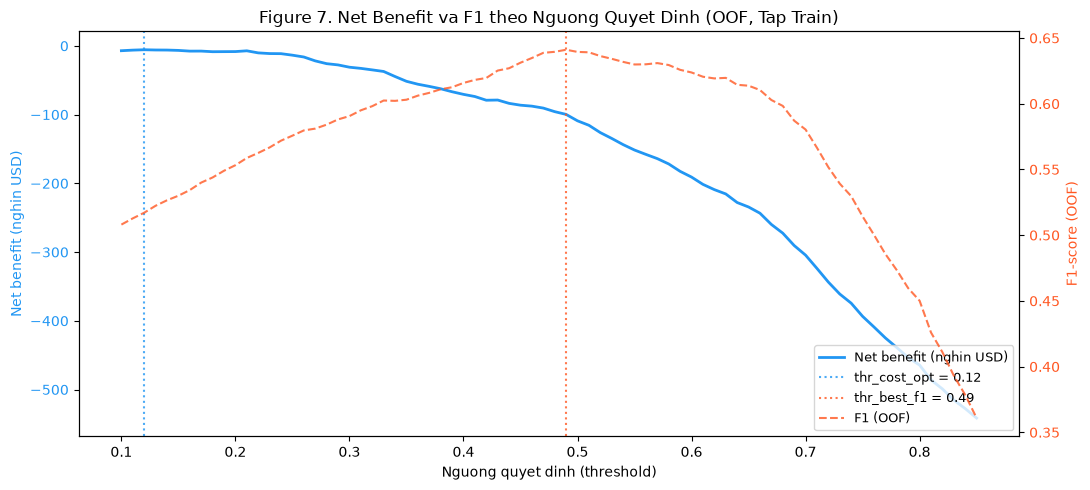

Da luu Figure 7 -> d:\DS66B_group_11\reports\figures\figure_cost_threshold_scan.png


In [69]:
# -- 4B.3: Figure 7 - Net Benefit va F1 theo nguong (OOF) -------------------
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(11, 5))
ax2 = ax1.twinx()

ax1.plot(cost_scan_df.index, cost_scan_df["net_benefit_usd"] / 1e3,
         color="#2196F3", lw=2, label="Net benefit (nghin USD)")
ax2.plot(thr_table.index, thr_table["f1"],
         color="#FF5722", lw=1.5, ls="--", alpha=0.8, label="F1 (OOF)")

ax1.axvline(thr_cost_opt, color="#2196F3", ls=":", alpha=0.8,
            label=f"thr_cost_opt = {thr_cost_opt:.2f}")
ax1.axvline(thr_best_f1, color="#FF5722", ls=":", alpha=0.8,
            label=f"thr_best_f1 = {thr_best_f1:.2f}")

ax1.set_xlabel("Nguong quyet dinh (threshold)")
ax1.set_ylabel("Net benefit (nghin USD)", color="#2196F3")
ax2.set_ylabel("F1-score (OOF)", color="#FF5722")
ax1.tick_params(axis='y', labelcolor="#2196F3")
ax2.tick_params(axis='y', labelcolor="#FF5722")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="lower right", fontsize=9)
ax1.set_title("Figure 7. Net Benefit va F1 theo Nguong Quyet Dinh (OOF, Tap Train)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_cost_threshold_scan.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Da luu Figure 7 -> {FIGURES_DIR / 'figure_cost_threshold_scan.png'}")


Ngưỡng tối ưu theo chi phí được chọn bằng điểm rủi ro thô OOF và hàm chi phí giả định đã khai báo. Sau đó, chính sách được áp dụng lên tập test với cùng thang điểm. Kết quả phụ thuộc vào chi phí và tỷ lệ thành công giả định; không nên mô tả đây là tỷ suất hoàn vốn (ROI) thực tế.


In [70]:
# -- 4B.4: Bang so sanh chien luoc tren Tap Test -----------------------------
from sklearn.metrics import confusion_matrix
from sklearn.linear_model import LogisticRegression as _LR_kaggle

# Baseline Logistic Regression, giữ preprocessor tuyến tính nhất quán.
_kaggle_pipe = make_pipeline(
    _LR_kaggle(max_iter=1000, random_state=RANDOM_STATE),
    preprocessor=preprocessor_linear,
)
_kaggle_pipe.fit(X_train, y_train)
_kaggle_proba_test = _kaggle_pipe.predict_proba(X_test)[:, 1]

def _strategy_row(name, preds, y_true):
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0, 1]).ravel()
    nb = net_benefit(tp, fp, fn, tn)
    return {
        "Chien luoc": name,
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
        "So khach lien he": int(tp + fp),
        "Net benefit (USD)": float(nb),
    }

n_test = len(y_test)
thr_recall80_val = thr_recall80 if thr_recall80 is not None else thr_best_f1
strategies = [
    _strategy_row("Khong can thiep", np.zeros(n_test, dtype=int), y_test),
    _strategy_row("Lien he tat ca", np.ones(n_test, dtype=int), y_test),
    _strategy_row(
        "Kaggle mac dinh (LR, thr=0.5)",
        (_kaggle_proba_test >= 0.5).astype(int),
        y_test,
    ),
    _strategy_row("Champion thr=0.50", (test_proba >= 0.50).astype(int), y_test),
    _strategy_row(
        f"Champion thr_best_f1={thr_best_f1:.2f}",
        (test_proba >= thr_best_f1).astype(int),
        y_test,
    ),
    _strategy_row(
        f"Champion thr_recall80={thr_recall80_val:.2f}",
        (test_proba >= thr_recall80_val).astype(int),
        y_test,
    ),
    _strategy_row(
        f"Champion thr_cost_opt={thr_cost_opt:.2f} (raw risk score)",
        (test_score_cost >= thr_cost_opt).astype(int),
        y_test,
    ),
]

policy_df = pd.DataFrame(strategies).set_index("Chien luoc")
baseline_nb = policy_df.loc[
    "Kaggle mac dinh (LR, thr=0.5)", "Net benefit (USD)"
]
policy_df["Chenh lech vs Kaggle (USD)"] = (
    policy_df["Net benefit (USD)"] - baseline_nb
)

print("Table 9. So sanh chien luoc tren Tap Test (gia dinh chi phi minh hoa)")
display(policy_df)
policy_df.to_csv(ARTIFACTS_DIR / "table_cost_policy_comparison_test.csv")
print(f"\nDa luu Table 9 -> {ARTIFACTS_DIR / 'table_cost_policy_comparison_test.csv'}")


Table 9. So sanh chien luoc tren Tap Test (gia dinh chi phi minh hoa)


,TP,FP,FN,TN,So khach lien he,Net benefit (USD),Chenh lech vs Kaggle (USD)
Chien luoc,,,,,,,
Khong can thiep,0,0,374,1035,0,-187000.0000,-110650.0000
Lien he tat ca,374,1035,0,0,1409,-14350.0000,62000.0000
"Kaggle mac dinh (LR, thr=0.5)",193,103,181,932,296,-76350.0000,0.0000
Champion thr=0.50,291,246,83,789,537,-24700.0000,51650.0000
Champion thr_best_f1=0.49,296,255,78,780,551,-22150.0000,54200.0000
Champion thr_recall80=0.44,304,293,70,742,597,-19250.0000,57100.0000
Champion thr_cost_opt=0.12 (raw risk score),367,663,7,372,1030,50.0000,76400.0000



Da luu Table 9 -> d:\DS66B_group_11\artifacts\table_cost_policy_comparison_test.csv


Bảng chính sách trong output đã thực thi so sánh các phương án liên hệ khách hàng khác nhau trên tập test độc lập. Theo các giả định minh họa, chính sách tối ưu theo chi phí đạt lợi ích ròng 50 USD trong lần chạy này. Đây là kết quả của một kịch bản giả định, không phải ước lượng lợi nhuận thực tế của công ty hay tác động nhân quả của hoạt động giữ chân khách hàng.


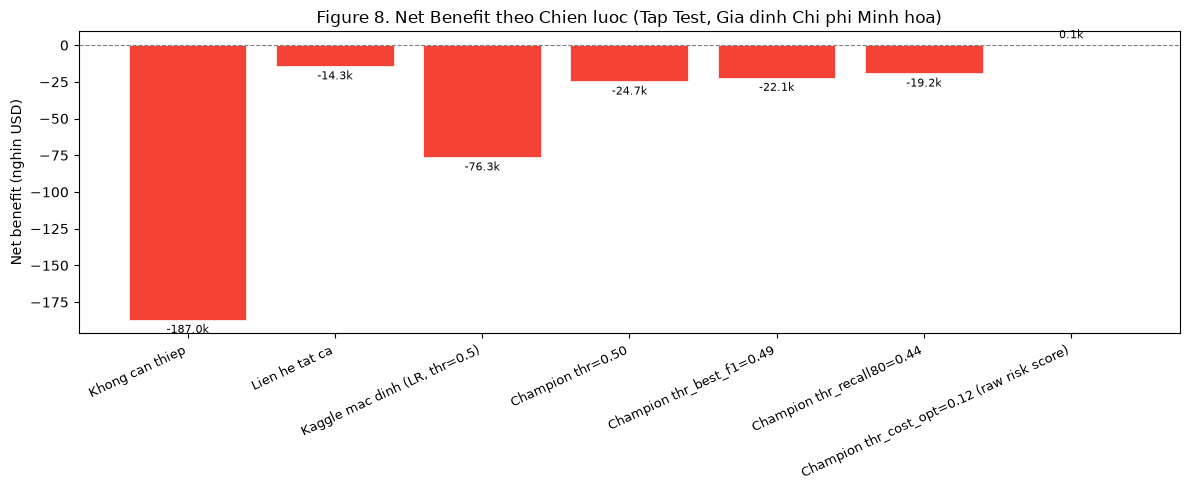

Da luu Figure 8 -> d:\DS66B_group_11\reports\figures\figure_cost_policy_comparison.png


In [71]:
# -- 4B.5: Figure 8 - Bieu do cot Net Benefit theo chien luoc ----------------
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(12, 5))
labels = list(policy_df.index)
values = policy_df["Net benefit (USD)"].values / 1e3
colors = ["#F44336" if v < 0 else "#4CAF50" for v in values]

bars = ax.bar(range(len(labels)), values, color=colors,
              edgecolor="white", linewidth=0.5)
ax.bar_label(bars, fmt=lambda x: f"{x:.1f}k", padding=3, fontsize=8)
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=25, ha="right", fontsize=9)
ax.set_ylabel("Net benefit (nghin USD)")
ax.set_title("Figure 8. Net Benefit theo Chien luoc (Tap Test, Gia dinh Chi phi Minh hoa)")
ax.axhline(0, color="gray", lw=0.8, ls="--")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_cost_policy_comparison.png",
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Da luu Figure 8 -> {FIGURES_DIR / 'figure_cost_policy_comparison.png'}")


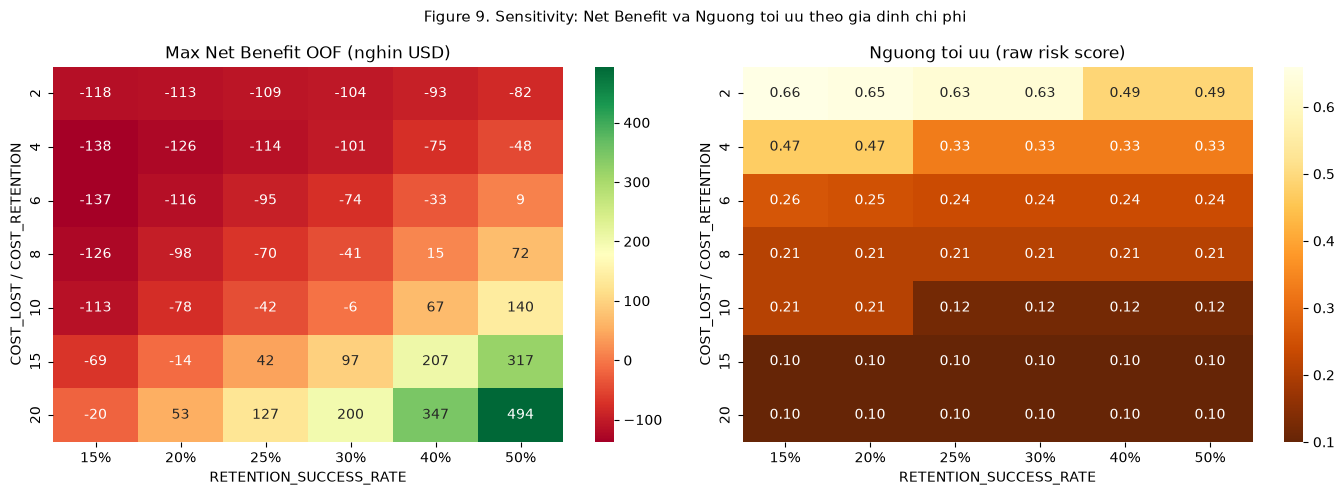

Da luu Figure 9 -> d:\DS66B_group_11\reports\figures\figure_cost_sensitivity.png
Da luu sensitivity table -> d:\DS66B_group_11\artifacts\table_cost_sensitivity.csv


In [72]:
# -- 4B.6: Phan tich do nhay (sensitivity analysis) --------------------------
loss_ratios = [2, 4, 6, 8, 10, 15, 20]
retention_rates = [0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

sensitivity_rows = []
for lr in loss_ratios:
    for rr in retention_rates:
        cost_ret = COST_RETENTION
        cost_lost = COST_RETENTION * lr
        best_nb = -np.inf
        best_thr = None
        for thr in thr_grid_cost:
            preds = (oof_score_cost >= thr).astype(int)
            tn, fp, fn, tp = confusion_matrix(y_train, preds, labels=[0, 1]).ravel()
            nb_val = net_benefit(
                tp, fp, fn, tn,
                cost_retention=cost_ret,
                cost_lost=cost_lost,
                retention_rate=rr,
            )
            if nb_val > best_nb:
                best_nb = nb_val
                best_thr = round(float(thr), 2)
        sensitivity_rows.append({
            "loss_ratio": lr,
            "retention_rate": rr,
            "optimal_threshold": best_thr,
            "max_net_benefit_oof": best_nb,
        })

sens_df = pd.DataFrame(sensitivity_rows)
pivot_nb = sens_df.pivot(index="loss_ratio", columns="retention_rate", values="max_net_benefit_oof")
pivot_thr = sens_df.pivot(index="loss_ratio", columns="retention_rate", values="optimal_threshold")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(pivot_nb / 1e3, ax=ax1, annot=True, fmt=".0f", cmap="RdYlGn",
            xticklabels=[f"{r:.0%}" for r in retention_rates], yticklabels=loss_ratios)
ax1.set_title("Max Net Benefit OOF (nghin USD)")
ax1.set_xlabel("RETENTION_SUCCESS_RATE")
ax1.set_ylabel("COST_LOST / COST_RETENTION")

sns.heatmap(pivot_thr, ax=ax2, annot=True, fmt=".2f", cmap="YlOrBr_r",
            xticklabels=[f"{r:.0%}" for r in retention_rates], yticklabels=loss_ratios)
ax2.set_title("Nguong toi uu (raw risk score)")
ax2.set_xlabel("RETENTION_SUCCESS_RATE")
ax2.set_ylabel("COST_LOST / COST_RETENTION")

fig.suptitle("Figure 9. Sensitivity: Net Benefit va Nguong toi uu theo gia dinh chi phi", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_cost_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Da luu Figure 9 -> {FIGURES_DIR / 'figure_cost_sensitivity.png'}")
sens_df.to_csv(ARTIFACTS_DIR / "table_cost_sensitivity.csv", index=False)
print(f"Da luu sensitivity table -> {ARTIFACTS_DIR / 'table_cost_sensitivity.csv'}")


Phân tích độ nhạy thay đổi chi phí tổn thất tương đối và tỷ lệ thành công giả định của hoạt động giữ chân khách hàng. Phân tích cho thấy chính sách được ưu tiên thay đổi như thế nào khi các giả định thay đổi; nó không thể xác thực các giả định đó hoặc chứng minh rằng một biện pháp can thiệp làm thay đổi hành vi khách hàng.


## 11. Tóm tắt phân tích chi phí

Phân tích kịch bản minh họa cách chi phí nghiệp vụ không đối xứng có thể hỗ trợ lựa chọn ngưỡng. Kết quả vẫn mang tính giả định cho đến khi chi phí và hiệu quả của biện pháp can thiệp được ước lượng từ dữ liệu vận hành hoặc một thí nghiệm phù hợp.


## 12. Độ tin cậy và khả năng diễn giải

Phần này phân biệt mối liên hệ thống kê, giải thích dựa trên mô hình và suy luận nhân quả. Odds Ratio mô tả mô hình Logistic Regression dùng làm đối chiếu, trong khi SHAP phân bổ mức đóng góp vào dự đoán của mô hình tốt nhất đã khớp. Không phương pháp nào trong hai phương pháp xác định tác động của việc can thiệp làm thay đổi một đặc trưng.
 Odds Ratio chỉ được diễn giải cho các biến không bị đa cộng tuyến nặng (xem phân loại theo VIF ở mục 12.1).

In [73]:
# -- 5A.0: Import cho Section 5 -----------------------------------------------
import statsmodels.api as sm
from statsmodels.tools import add_constant
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

try:
    import statsmodels.tools.sm_exceptions as _sme
    warnings.filterwarnings("ignore", category=_sme.ConvergenceWarning)
except Exception:
    pass
print("Import Section 5 hoan tat.")


Import Section 5 hoan tat.


In [74]:
# -- 5A.1: Tien xu ly bang preprocessor_linear -> fit statsmodels.Logit tren Train ----
from sklearn.base import clone as _clone_sm

# preprocessor_linear da dinh nghia o Section 2B (bo Total_Services_Count)
_prep_sm = _clone_sm(preprocessor_linear)
X_train_fe_sm = engineering_domain_features(X_train)
X_train_proc_sm = _prep_sm.fit_transform(X_train_fe_sm)  # chi fit tren Train

# Them hang so (intercept)
X_train_sm_arr = add_constant(X_train_proc_sm.values.astype(float), has_constant='add')
col_names_sm = ["const"] + list(X_train_proc_sm.columns)
y_train_sm_arr = y_train.values

print(f"Ma tran tien xu ly: {X_train_sm_arr.shape} (co hang so)")

# Kiem tra thu hang ma tran
import numpy.linalg as nla
rank = nla.matrix_rank(X_train_sm_arr)
print(f"Thu hang ma tran: {rank} (can = {X_train_sm_arr.shape[1]} de khong suy bien)")
if rank < X_train_sm_arr.shape[1]:
    print("CANH BAO: Ma tran van suy bien! statsmodels.Logit co the khong hoi tu.")
else:
    print("OK: Ma tran du thu hang - statsmodels.Logit se hoi tu.")


Ma tran tien xu ly: (5634, 28) (co hang so)
Thu hang ma tran: 28 (can = 28 de khong suy bien)
OK: Ma tran du thu hang - statsmodels.Logit se hoi tu.


In [75]:
# -- 5A.2: Fit statsmodels.Logit va tinh McFadden pseudo-R2 ------------------
import statsmodels.api as sm

logit_model = sm.Logit(y_train_sm_arr, X_train_sm_arr)
logit_result = logit_model.fit(disp=0, maxiter=200)

print("\n=== Ket qua hoi quy Logit (statsmodels, khong phat) ===")
print(f"So quan sat      : {int(logit_result.nobs):,}")
print(f"Log-likelihood   : {logit_result.llf:.4f}")
print(f"Log-likelihood 0 : {logit_result.llnull:.4f}")
print(f"AIC              : {logit_result.aic:.4f}")
print(f"McFadden R2      : {logit_result.prsquared:.4f}")
print()
pr2 = logit_result.prsquared
if pr2 < 0.1:
    interp = "Khop yeu (< 0,10)"
elif pr2 < 0.2:
    interp = "Khop trung binh (0,10-0,20)"
elif pr2 < 0.4:
    interp = "Khop tot (0,20-0,40) - nguong thuong chap nhan trong thuc hanh"
else:
    interp = "Khop rat tot (> 0,40)"
print(f"Dien giai: R2 = {pr2:.4f} -> {interp}")

# So sanh voi LR-tuned (co phat C nho)
from sklearn.metrics import log_loss
import numpy as np
ll_null_val = -log_loss(y_train, np.full(len(y_train), y_train.mean())) * len(y_train)
logreg_proba_train = logreg_pipeline.predict_proba(X_train)[:, 1]
ll_model_val = -log_loss(y_train, logreg_proba_train) * len(y_train)
pr2_penalized = 1 - ll_model_val / ll_null_val
print(f"\nLR-tuned (co phat): pseudo-R2 ~ {pr2_penalized:.4f} [tinh tu log-loss, khong phai MLE]")
print("  Luu y: hai chi so KHONG so sanh truc tiep vi LR-tuned co phat manh (C nho)")
print("  con statsmodels.Logit la MLE khong phat.")



=== Ket qua hoi quy Logit (statsmodels, khong phat) ===
So quan sat      : 5,634
Log-likelihood   : -2310.0181
Log-likelihood 0 : -3259.7314
AIC              : 4676.0362
McFadden R2      : 0.2913

Dien giai: R2 = 0.2913 -> Khop tot (0,20-0,40) - nguong thuong chap nhan trong thuc hanh

LR-tuned (co phat): pseudo-R2 ~ 0.1474 [tinh tu log-loss, khong phai MLE]
  Luu y: hai chi so KHONG so sanh truc tiep vi LR-tuned co phat manh (C nho)
  con statsmodels.Logit la MLE khong phat.


In [76]:
# -- 5A.3: Bang Odds Ratio, CI 95%, p-value ----------------------------------
params = np.asarray(logit_result.params)
odds_ratios_vals = np.exp(params)
ci = np.asarray(logit_result.conf_int())
ci_lower = np.exp(ci[:, 0])
ci_upper = np.exp(ci[:, 1])
pvalues = np.asarray(logit_result.pvalues)

or_df = pd.DataFrame({
    "He so beta": params,
    "Odds Ratio": odds_ratios_vals,
    "CI_lower_95": ci_lower,
    "CI_upper_95": ci_upper,
    "p-value": pvalues,
    "Y nghia (p<0.05)": pvalues < 0.05,
}, index=col_names_sm)

or_df = or_df.drop("const", errors="ignore").sort_values("Odds Ratio", ascending=False)
print("Table 10. He so beta va Odds Ratio (statsmodels.Logit, khong phat)")
print("  Nhom tham chieu theo drop='first'")
print("  Bien so da StandardScaler: OR la thay doi theo 1 standard deviation.")
print("  Cac OR la association, khong phai tac dong nhan qua.\n")
display(or_df.round(4))
or_df.to_csv(ARTIFACTS_DIR / "table_odds_ratios_statsmodels.csv")
print(f"Da luu Table 10 -> {ARTIFACTS_DIR / 'table_odds_ratios_statsmodels.csv'}")


Table 10. He so beta va Odds Ratio (statsmodels.Logit, khong phat)
  Nhom tham chieu theo drop='first'
  Bien so da StandardScaler: OR la thay doi theo 1 standard deviation.
  Cac OR la association, khong phai tac dong nhan qua.



,He so beta,Odds Ratio,CI_lower_95,CI_upper_95,p-value,Y nghia (p<0.05)
InternetService_Fiber optic,2.8015,16.4698,2.8324,95.7665,0.0018,True
StreamingTV_Yes,1.0351,2.8155,1.3706,5.7838,0.0048,True
StreamingMovies_Yes,1.0338,2.8118,1.3674,5.7821,0.0049,True
PhoneService_Yes,1.0141,2.7567,0.6604,11.5069,0.1642,False
MultipleLines_Yes,0.7251,2.0650,1.3964,3.0537,0.0003,True
Tenure_Cohort_>48,0.6010,1.8239,0.8249,4.0330,0.1377,False
DeviceProtection_Yes,0.3871,1.4727,0.9975,2.1741,0.0515,False
PaperlessBilling_Yes,0.3787,1.4604,1.2387,1.7218,0.0000,True
PaymentMethod_Electronic check,0.3759,1.4563,1.1826,1.7933,0.0004,True
TotalCharges,0.2585,1.2950,0.9052,1.8527,0.1571,False


Da luu Table 10 -> d:\DS66B_group_11\artifacts\table_odds_ratios_statsmodels.csv


In [77]:
# -- 5A.3b: Phan loai Odds Ratio theo muc do tin cay (dua tren VIF) --------------------
# Da cong tuyen lam phong dai sai so chuan va CI cua he so cac bien nam trong nhom chong lan;
# he so cua cac bien ngoai nhom gan nhu khong bi anh huong. Vi vay OR duoc phan loai theo VIF
# cua chinh ma tran preprocessor_linear da dung de fit Logit (vif_linear_prep o Section 5.1).
VIF_OK, VIF_CAUTION = 5, 10     # nguong quy uoc: <5 on dinh; 5-10 than trong; >10 khong dien giai

vif_map = vif_linear_prep.set_index("Feature")["VIF"]
or_df["VIF"] = vif_map.reindex(or_df.index)
assert or_df["VIF"].notna().all(), "Ten bien trong or_df va vif_linear_prep khong khop"

def _interp_level(v):
    if v < VIF_OK:
        return "Dien giai duoc"
    if v <= VIF_CAUTION:
        return "Than trong"
    return "Khong dien giai"

or_df["Muc_dien_giai"] = or_df["VIF"].apply(_interp_level)
or_df.to_csv(ARTIFACTS_DIR / "table_odds_ratios_by_reliability.csv")

_cols = ["Odds Ratio", "CI_lower_95", "CI_upper_95", "p-value", "VIF"]
print("Table 10b. Odds Ratio theo muc do tin cay (VIF cua ma tran preprocessor_linear)")
print(or_df["Muc_dien_giai"].value_counts().to_string(), "\n")

print("Nhom 1 - Dien giai duoc (VIF < 5):")
display(or_df[or_df["Muc_dien_giai"] == "Dien giai duoc"][_cols]
        .sort_values("Odds Ratio", ascending=False).round(4))

print("Nhom 2 - Than trong (5 <= VIF <= 10):")
display(or_df[or_df["Muc_dien_giai"] == "Than trong"][_cols]
        .sort_values("Odds Ratio", ascending=False).round(4))

_not_interp = or_df[or_df["Muc_dien_giai"] == "Khong dien giai"].sort_values("VIF", ascending=False)
print("Nhom 3 - Khong dien giai (VIF > 10): "
      + ", ".join(f"{k} (VIF={v:.1f})" for k, v in _not_interp["VIF"].items()))
print(f"Da luu Table 10b -> {ARTIFACTS_DIR / 'table_odds_ratios_by_reliability.csv'}")


Table 10b. Odds Ratio theo muc do tin cay (VIF cua ma tran preprocessor_linear)
Muc_dien_giai
Dien giai duoc     12
Khong dien giai     9
Than trong          6 

Nhom 1 - Dien giai duoc (VIF < 5):


,Odds Ratio,CI_lower_95,CI_upper_95,p-value,VIF
PaperlessBilling_Yes,1.4604,1.2387,1.7218,0.0000,1.2111
PaymentMethod_Electronic check,1.4563,1.1826,1.7933,0.0004,1.9763
SeniorCitizen_1,1.1666,0.9684,1.4054,0.1047,1.1542
PaymentMethod_Mailed check,1.0690,0.8286,1.3791,0.6078,1.8638
Partner_Yes,1.0332,0.8708,1.2260,0.7081,1.4523
gender_Male,1.0224,0.8859,1.1799,0.7620,1.0043
Charge_Ratio,0.9946,0.9288,1.0650,0.8770,1.0064
PaymentMethod_Credit card (automatic),0.9923,0.7714,1.2764,0.9520,1.5568
Dependents_Yes,0.8089,0.6635,0.9862,0.0359,1.3765
Tenure_Cohort_12-24,0.7283,0.5477,0.9684,0.0292,1.9871


Nhom 2 - Than trong (5 <= VIF <= 10):


,Odds Ratio,CI_lower_95,CI_upper_95,p-value,VIF
MultipleLines_Yes,2.0650,1.3964,3.0537,0.0003,7.2549
DeviceProtection_Yes,1.4727,0.9975,2.1741,0.0515,6.9469
OnlineBackup_Yes,1.2462,0.8481,1.8310,0.2623,6.7468
TechSupport_Yes,1.0510,0.7057,1.5653,0.8067,6.5197
OnlineSecurity_Yes,0.9895,0.6668,1.4683,0.9582,6.3815
Tenure_Cohort_24-48,0.9730,0.6069,1.5598,0.9095,6.8163


Nhom 3 - Khong dien giai (VIF > 10): MonthlyCharges (VIF=862.6), InternetService_Fiber optic (VIF=147.9), InternetService_No (VIF=103.2), PhoneService_Yes (VIF=35.3), tenure (VIF=27.1), StreamingTV_Yes (VIF=24.0), StreamingMovies_Yes (VIF=24.0), Tenure_Cohort_>48 (VIF=23.4), TotalCharges (VIF=11.5)
Da luu Table 10b -> d:\DS66B_group_11\artifacts\table_odds_ratios_by_reliability.csv


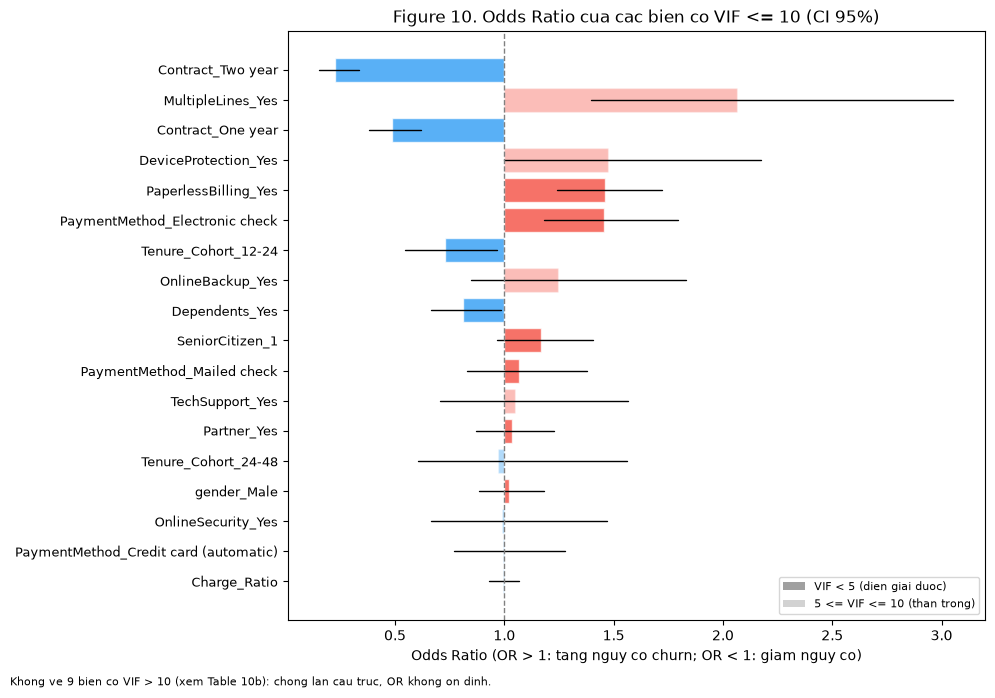

Da luu Figure 10 -> d:\DS66B_group_11\reports\figures\figure_odds_ratios_statsmodels.png


In [78]:
# -- 5A.4: Figure 10 - Odds Ratio bieu do (chi cac bien co VIF <= 10) --------------
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

plot_df = or_df[or_df["Muc_dien_giai"] != "Khong dien giai"].copy()
plot_df["abs_log_or"] = np.abs(np.log(plot_df["Odds Ratio"].clip(1e-6)))
plot_df = plot_df.sort_values("abs_log_or", ascending=True)
n_excluded = int((or_df["Muc_dien_giai"] == "Khong dien giai").sum())

fig, ax = plt.subplots(figsize=(10, max(6, len(plot_df) * 0.38)))
for i, (_, row) in enumerate(plot_df.iterrows()):
    color = "#F44336" if row["Odds Ratio"] > 1 else "#2196F3"
    alpha = 0.75 if row["Muc_dien_giai"] == "Dien giai duoc" else 0.35
    ax.barh(i, row["Odds Ratio"] - 1, left=1, color=color, alpha=alpha, edgecolor="white")
    ax.plot([row["CI_lower_95"], row["CI_upper_95"]], [i, i],
            color="black", lw=1, solid_capstyle="round")

ax.axvline(1.0, color="gray", lw=1, ls="--")
ax.set_yticks(range(len(plot_df)))
ax.set_yticklabels(plot_df.index, fontsize=9)
ax.set_xlabel("Odds Ratio (OR > 1: tang nguy co churn; OR < 1: giam nguy co)")
ax.set_title("Figure 10. Odds Ratio cua cac bien co VIF <= 10 (CI 95%)")
ax.legend(handles=[Patch(facecolor="gray", alpha=0.75, label="VIF < 5 (dien giai duoc)"),
                   Patch(facecolor="gray", alpha=0.35, label="5 <= VIF <= 10 (than trong)")],
          loc="lower right", fontsize=8)
fig.text(0.01, -0.01, f"Khong ve {n_excluded} bien co VIF > 10 (xem Table 10b): chong lan cau truc, OR khong on dinh.",
         fontsize=8, ha="left")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "figure_odds_ratios_statsmodels.png",
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Da luu Figure 10 -> {FIGURES_DIR / 'figure_odds_ratios_statsmodels.png'}")


### 12.1. Odds Ratio của Logistic Regression

Odds Ratio được lấy từ `statsmodels.Logit` không phạt, khớp trên biểu diễn `preprocessor_linear`. Với biến phân loại, OR so sánh nhóm đã mã hóa với nhóm tham chiếu (`drop='first'`: hợp đồng theo tháng, thanh toán chuyển khoản tự động, nhóm `Tenure_Cohort` 0–12 tháng). Các biến số được chuẩn hóa nên OR của chúng ứng với mức tăng một độ lệch chuẩn. OR cho biết odds rời bỏ thay đổi bao nhiêu lần khi các biến còn lại giữ cố định; đây là liên hệ thống kê, không phải tác động nhân quả.

**Quy tắc diễn giải theo VIF.** Mục 5.1 cho thấy sau khi loại `Total_Services_Count`, đa cộng tuyến vẫn còn cao ở một số biến. Đa cộng tuyến làm phình sai số chuẩn và khoảng tin cậy của hệ số các biến nằm trong nhóm chồng lấn, còn hệ số của các biến nằm ngoài nhóm gần như không bị ảnh hưởng, và khả năng dự đoán của mô hình cũng không bị ảnh hưởng. Do đó OR được chia ba mức theo VIF của chính ma trận đã khớp (Table 10b): VIF dưới 5 là diễn giải được, từ 5 đến 10 là diễn giải thận trọng, trên 10 là không diễn giải. Các ngưỡng 5 và 10 là quy ước thực hành, không phải ngưỡng thống kê chặt chẽ, và p-value ở đây chưa hiệu chỉnh cho việc kiểm định đồng thời nhiều hệ số.

**Nhóm diễn giải được (VIF < 5).**
- Hợp đồng là yếu tố có liên hệ mạnh và ổn định nhất: so với hợp đồng theo tháng, hợp đồng 2 năm có OR = 0,23 (CI 95%: 0,15–0,34) và hợp đồng 1 năm có OR = 0,49 (CI: 0,38–0,62), cả hai đều có p < 0,001.
- `PaperlessBilling_Yes` (OR = 1,46; CI: 1,24–1,72) và thanh toán bằng `Electronic check` so với chuyển khoản tự động (OR = 1,46; CI: 1,18–1,79) gắn với odds rời bỏ cao hơn.
- `Dependents_Yes` (OR = 0,81; CI: 0,66–0,99) và `Tenure_Cohort_12-24` so với nhóm 0–12 tháng (OR = 0,73; CI: 0,55–0,97) gắn với odds thấp hơn, nhưng khoảng tin cậy sát 1 nên mức liên hệ nhỏ.
- `SeniorCitizen_1`, `Partner_Yes`, `gender_Male`, `Charge_Ratio` và các phương thức thanh toán còn lại có khoảng tin cậy chứa 1, nên mẫu này không đủ bằng chứng về liên hệ riêng của chúng.

**Nhóm thận trọng (5 ≤ VIF ≤ 10).** `MultipleLines_Yes` có OR = 2,07 (CI: 1,40–3,05; VIF = 7,25) và là biến duy nhất trong nhóm này có ý nghĩa thống kê rõ ràng, nhưng khoảng tin cậy có thể đã bị phình do chồng lấn với các biến dịch vụ. `DeviceProtection_Yes` có CI sát 1 (0,9975–2,17); `OnlineBackup_Yes`, `TechSupport_Yes`, `OnlineSecurity_Yes` và `Tenure_Cohort_24-48` có CI chứa 1.

**Nhóm không diễn giải (VIF > 10).** Gồm `MonthlyCharges`, `InternetService_Fiber optic`, `InternetService_No`, `PhoneService_Yes`, `tenure`, `StreamingTV_Yes`, `StreamingMovies_Yes`, `Tenure_Cohort_>48` và `TotalCharges`. Các hệ số này có độ lớn cực đoan cùng khoảng tin cậy rất rộng, ví dụ `InternetService_Fiber optic` có OR = 16,47 (CI: 2,83–95,77), `InternetService_No` có OR = 0,064 (CI: 0,011–0,377) và `MonthlyCharges` có OR = 0,097 (CI: 0,012–0,800). Đây là dấu hiệu của chồng lấn cấu trúc, không phải kết luận kinh doanh, nên Figure 10 không vẽ nhóm này. Mức đóng góp của các biến này vào dự đoán được xem xét bằng SHAP ở mục 12.2.

### 12.2. SHAP cho mô hình Random Forest được chọn

Giá trị SHAP phân rã output của mô hình đã khớp so với một giá trị cơ sở kỳ vọng đối với biểu diễn đặc trưng đã mã hóa. Chúng hỗ trợ giải thích dự đoán ở cấp độ từng quan sát và toàn cục. SHAP không cho thấy rằng thay đổi một đặc trưng sẽ làm thay đổi churn, và không được trình bày như tác động nhân quả.


In [79]:
# -- 5B.1: Chuan bi du lieu cho SHAP (bo buoc SMOTE khi giai thich) ----------
import shap
import numpy as np
import warnings
warnings.filterwarnings("ignore")

_cp = champion_pipeline

# Bien doi X_test qua domain_features va preprocess (bo SMOTE)
X_test_fe_shap = _cp.named_steps["domain_features"].transform(X_test)
X_test_proc_shap = _cp.named_steps["preprocess"].transform(X_test_fe_shap)

try:
    feature_names_shap = list(_cp.named_steps["preprocess"].get_feature_names_out())
except Exception:
    feature_names_shap = [f"feat_{i}" for i in range(X_test_proc_shap.shape[1])]

# Lay model (buoc cuoi)
_model_step = _cp.steps[-1][1]
print(f"Champion: {champion_name}")
print(f"Model type: {type(_model_step).__name__}")
print(f"So dac trung sau tien xu ly: {X_test_proc_shap.shape[1]}")

X_test_arr_shap = (X_test_proc_shap.values
                   if hasattr(X_test_proc_shap, 'values')
                   else X_test_proc_shap)

# Background set tu X_train (subsample 200)
X_train_fe_shap = _cp.named_steps["domain_features"].transform(X_train)
X_train_proc_shap = _cp.named_steps["preprocess"].transform(X_train_fe_shap)
X_train_arr_shap = (X_train_proc_shap.values
                    if hasattr(X_train_proc_shap, 'values')
                    else X_train_proc_shap)

_rng = np.random.default_rng(42)
_bg_idx = _rng.choice(len(X_train_arr_shap),
                       size=min(200, len(X_train_arr_shap)), replace=False)
X_bg_shap = X_train_arr_shap[_bg_idx]
print(f"Background set: {X_bg_shap.shape}")


Champion: RF-tuned
Model type: RandomForestClassifier
So dac trung sau tien xu ly: 28
Background set: (200, 28)


C:\Users\LENOVO\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [80]:
# -- 5B.2: Tinh SHAP values --------------------------------------------------
import shap
import numpy as np

_model_type_name = type(_model_step).__name__
tree_types = ["RandomForestClassifier", "DecisionTreeClassifier",
              "XGBClassifier", "GradientBoostingClassifier", "ExtraTreesClassifier"]

if _model_type_name in tree_types:
    explainer = shap.TreeExplainer(_model_step,
                                   feature_perturbation="tree_path_dependent")
    shap_values_raw = explainer.shap_values(X_test_arr_shap)
    if isinstance(shap_values_raw, list):
        shap_vals_churn = shap_values_raw[1]
    elif hasattr(shap_values_raw, 'ndim') and shap_values_raw.ndim == 3:
        shap_vals_churn = shap_values_raw[:, :, 1]
    else:
        shap_vals_churn = shap_values_raw
    ev = explainer.expected_value
    expected_value_shap = ev[1] if isinstance(ev, (list, np.ndarray)) else ev
else:
    explainer = shap.LinearExplainer(_model_step, X_bg_shap,
                                     feature_perturbation="correlation_dependent")
    shap_values_raw = explainer.shap_values(X_test_arr_shap)
    if isinstance(shap_values_raw, list):
        shap_vals_churn = shap_values_raw[1]
    else:
        shap_vals_churn = shap_values_raw
    ev = explainer.expected_value
    expected_value_shap = ev[1] if isinstance(ev, (list, np.ndarray)) else ev

print(f"SHAP values shape: {shap_vals_churn.shape}")
print(f"Expected value (lop churn): {float(expected_value_shap):.4f}")


SHAP values shape: (1409, 28)
Expected value (lop churn): 0.5003


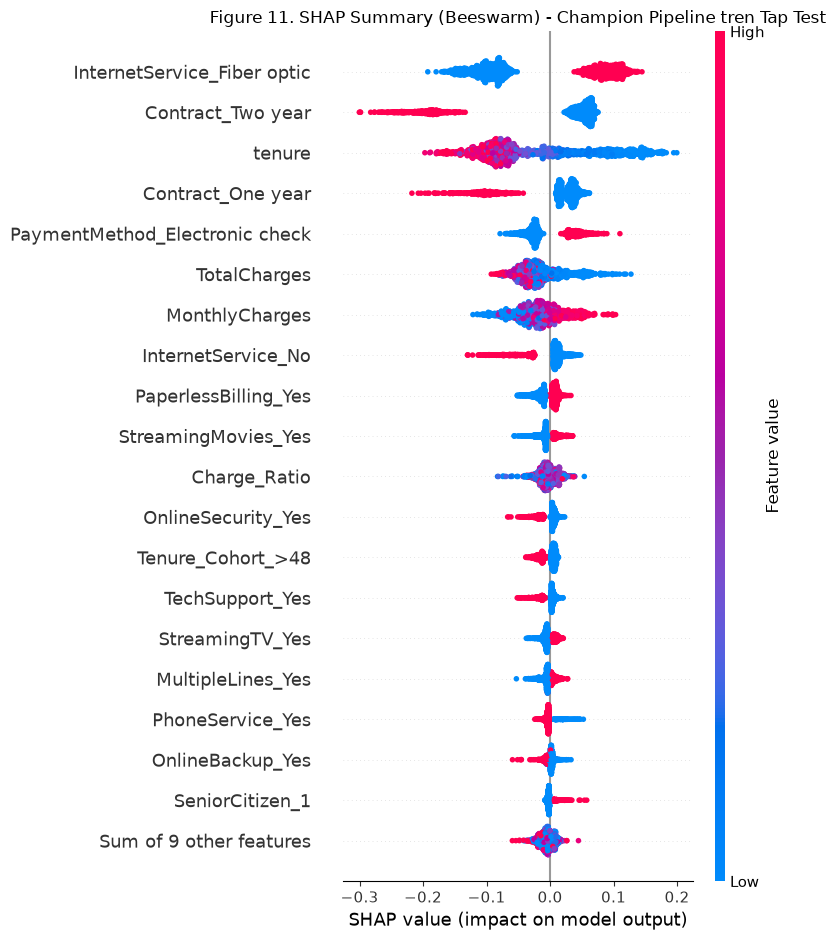

Da luu Figure 11 -> d:\DS66B_group_11\reports\figures\figure_shap_beeswarm_new.png


In [81]:
# -- 5B.3: Figure 11 - SHAP Summary (Beeswarm) ------------------------------
import matplotlib.pyplot as plt
import shap
import numpy as np

# Dung array base_values de tuong thich hoan hao voi cac plot trong shap 0.52+
base_vals_arr = np.full(len(X_test_arr_shap), float(expected_value_shap))

shap_expl = shap.Explanation(
    values=shap_vals_churn,
    base_values=base_vals_arr,
    data=X_test_arr_shap,
    feature_names=feature_names_shap,
)

plt.figure(figsize=(10, 8))
shap.plots.beeswarm(shap_expl, max_display=20, show=False)
plt.title("Figure 11. SHAP Summary (Beeswarm) - Champion Pipeline tren Tap Test")
plt.tight_layout()
fig11 = plt.gcf()
fig11.savefig(FIGURES_DIR / "figure_shap_beeswarm_new.png",
              dpi=150, bbox_inches="tight")
plt.show()
print(f"Da luu Figure 11 -> {FIGURES_DIR / 'figure_shap_beeswarm_new.png'}")


Biểu đồ beeswarm SHAP tóm tắt hướng và độ lớn đóng góp của các đặc trưng trên các khách hàng trong tập test, theo thang output của bộ giải thích. Giá trị dương và âm cho biết output mô hình dịch chuyển so với mức cơ sở; chúng không nhất thiết tương ứng với mức tăng hoặc giảm tính bằng điểm phần trăm của xác suất churn ngoài thực tế.


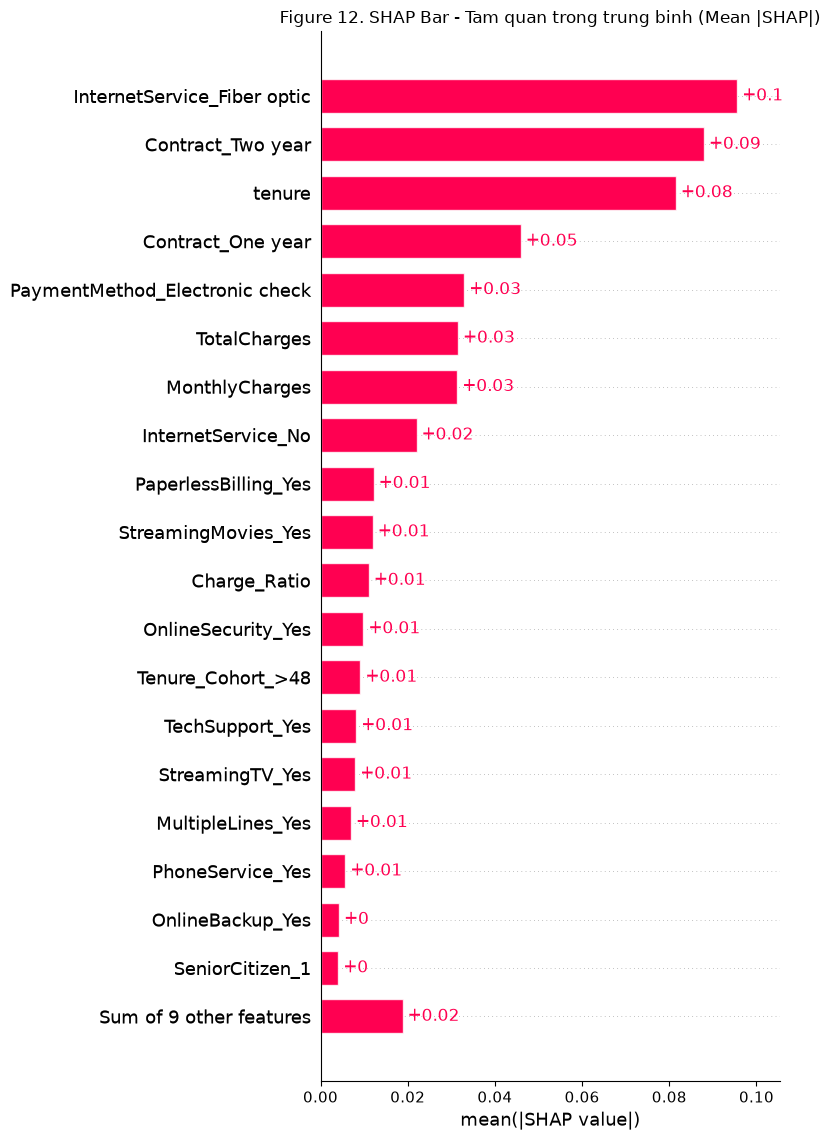

Da luu Figure 12 -> d:\DS66B_group_11\reports\figures\figure_shap_bar_new.png


In [82]:
# -- 5B.4: Figure 12 - SHAP Bar (Mean |SHAP|) --------------------------------
import matplotlib.pyplot as plt
import shap

plt.figure(figsize=(9, 7))
shap.plots.bar(shap_expl, max_display=20, show=False)
plt.title("Figure 12. SHAP Bar - Tam quan trong trung binh (Mean |SHAP|)")
plt.tight_layout()
fig12 = plt.gcf()
fig12.savefig(FIGURES_DIR / "figure_shap_bar_new.png",
              dpi=150, bbox_inches="tight")
plt.show()
print(f"Da luu Figure 12 -> {FIGURES_DIR / 'figure_shap_bar_new.png'}")


Biểu đồ thanh SHAP xếp hạng đặc trưng theo giá trị tuyệt đối trung bình của mức đóng góp. Biểu đồ mô tả mức độ mô hình Random Forest đã khớp dựa vào từng đặc trưng để dự đoán; không nên diễn giải đây là độ lớn tác động thống kê đơn biến hoặc mức độ quan trọng mang tính nhân quả.


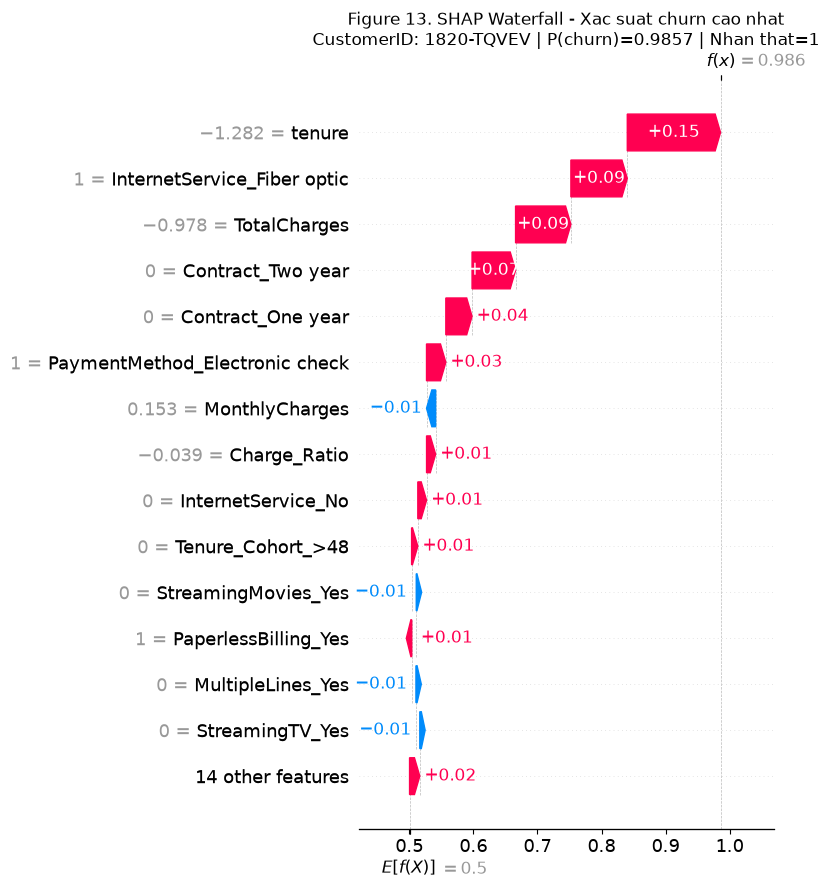

Da luu Figure 13 -> d:\DS66B_group_11\reports\figures\figure_shap_waterfall_cao_nhat.png
  CustomerID: 1820-TQVEV, P(churn)=0.9857, Nhan that=1


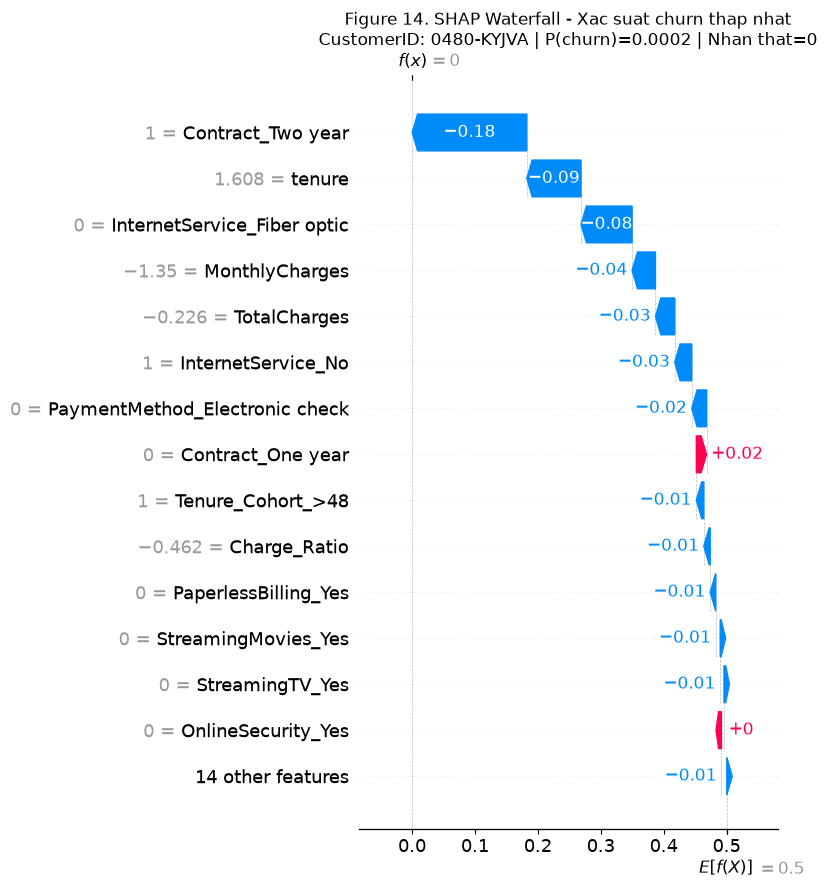

Da luu Figure 14 -> d:\DS66B_group_11\reports\figures\figure_shap_waterfall_thap_nhat.png
  CustomerID: 0480-KYJVA, P(churn)=0.0002, Nhan that=0


In [83]:
# -- 5B.5: Figure 13 & 14 - SHAP Waterfall cho 2 khach tieu bieu ------------
import matplotlib.pyplot as plt
import numpy as np
import shap

try:
    customer_ids = X_test.index.tolist()
except Exception:
    customer_ids = list(range(len(X_test)))

idx_high = int(np.argmax(test_proba))
idx_low  = int(np.argmin(test_proba))

for idx, label, fignum in [(idx_high, "cao_nhat", 13), (idx_low, "thap_nhat", 14)]:
    cid  = customer_ids[idx] if idx < len(customer_ids) else idx
    prob = test_proba[idx]
    true_lbl = int(y_test.iloc[idx] if hasattr(y_test, 'iloc') else y_test[idx])

    expl_single = shap.Explanation(
        values=shap_vals_churn[idx],
        base_values=float(expected_value_shap),
        data=X_test_arr_shap[idx],
        feature_names=feature_names_shap,
    )

    plt.figure(figsize=(10, 7))
    shap.plots.waterfall(expl_single, max_display=15, show=False)
    title_label = label.replace('_', ' ')
    plt.title(
        f"Figure {fignum}. SHAP Waterfall - Xac suat churn {title_label}\n"
        f"CustomerID: {cid} | P(churn)={prob:.4f} | Nhan that={true_lbl}"
    )
    plt.tight_layout()
    fig_wf = plt.gcf()
    fname_wf = f"figure_shap_waterfall_{label}.png"
    fig_wf.savefig(FIGURES_DIR / fname_wf, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Da luu Figure {fignum} -> {FIGURES_DIR / fname_wf}")
    print(f"  CustomerID: {cid}, P(churn)={prob:.4f}, Nhan that={true_lbl}")


Các biểu đồ waterfall minh họa hai trường hợp test riêng lẻ: khách hàng có điểm dự đoán cao nhất và thấp nhất trong output dự đoán test đã thực thi. Đây là ví dụ về cách mô hình phân rã dự đoán cá nhân, không phải ước lượng đại diện cho khách hàng điển hình hoặc bằng chứng về tác động của biện pháp can thiệp.


### 12.3. Hàm ý đối với phân tích giữ chân khách hàng

Các giải thích từ mô hình có thể gợi ý giả thuyết để nghiên cứu thêm, nhưng không xác định được biện pháp giữ chân khách hàng nào sẽ có hiệu quả.


Các mối liên hệ quan sát được gợi ý một số nhóm khách hàng có thể cần theo dõi hoặc liên hệ thêm, bao gồm khách hàng có hợp đồng theo tháng, thời gian sử dụng ngắn, dịch vụ Fiber optic hoặc phương thức thanh toán Electronic check. Đây là các giả thuyết để xác định nhóm mục tiêu, chưa phải nhóm đã được chứng minh sẽ phản hồi với can thiệp. Muốn xác định liệu ưu đãi hợp đồng, hỗ trợ giai đoạn đầu hay thay đổi dịch vụ có làm giảm churn hay không, cần có thí nghiệm có đối chứng hoặc một phương pháp đánh giá nhân quả đáng tin cậy khác. Việc áp dụng ngưỡng chi phí vào vận hành cũng đòi hỏi ước lượng chi phí có cơ sở và bằng chứng về hiệu quả can thiệp.


## 13. Tóm tắt phần 5

Notebook kết hợp một mô hình dự đoán được chọn, một mô hình tuyến tính dễ diễn giải để đối chiếu, các khoảng bất định bootstrap, chẩn đoán hiệu chuẩn và phần giải thích bằng SHAP. Mỗi thành phần trả lời một câu hỏi khác nhau; khi kết hợp lại, chúng vẫn không đủ căn cứ để đưa ra một kết luận nhân quả hoặc tài chính duy nhất.


## 14. Hạn chế, nguy cơ đối với tính hợp lệ và kết luận

**Hạn chế.** Bộ dữ liệu là một ảnh chụp dạng bảng tại một thời điểm và không hỗ trợ thiết kế dự đoán theo thời gian. Phép chia ngẫu nhiên có phân tầng đánh giá hiệu năng trên các quan sát giữ lại từ cùng bộ dữ liệu, chứ không đánh giá độ bền vững trước sự thay đổi dữ liệu ở các giai đoạn tương lai. Siêu tham số và mô hình tốt nhất được chọn bằng chính các fold train đóng góp vào ước lượng CV được báo cáo, nên chưa có ước lượng độc lập từ nested cross-validation. Phép so sánh SMOTE bị giới hạn bởi việc áp dụng SMOTE sau one-hot encoding. Hiệu chuẩn, giả định chi phí và phần giải thích SHAP cũng có những hạn chế diễn giải như đã nêu ở trên.

**Kết luận.** Theo quy trình lựa chọn đã xác định trước, `RF-tuned` được chọn dựa trên F1 CV trung bình (0,6394), trong khi `XGB-tuned` có các chỉ số xếp hạng CV tốt hơn (ROC-AUC 0,8488; Average Precision 0,6630). Tại ngưỡng 0,49 được chọn từ OOF, Random Forest đạt F1 test = 0,6400, recall = 0,7914, precision = 0,5372, ROC-AUC = 0,8451 và Average Precision = 0,6545. Các kết quả này hỗ trợ việc so sánh thực nghiệm giữa các pipeline phân loại và ngưỡng quyết định. Chúng không chứng minh tác động nhân quả của hoạt động giữ chân khách hàng, ROI thực tế hoặc ưu thế phổ quát của một mô hình.

**Hướng nghiên cứu tiếp theo.** Các đánh giá tiếp theo nên xem xét xác thực theo thời gian, nested hoặc repeated cross-validation, hiệu chuẩn xác suất khi cần, chi phí can thiệp được ước lượng từ dữ liệu thực nghiệm và thử nghiệm triển khai hoặc A/B testing đối với các biện pháp giữ chân khách hàng. Notebook hiện tại chưa cung cấp bằng chứng cho những kết luận bổ sung đó.


In [84]:
# Final self-check
assert RAW_DATA_PATH is not None
assert len(customers) == len(customers_raw)
assert set(X_train.index).isdisjoint(X_test.index)
assert features_to_drop == []
assert "Total_Services_Count" not in UPDATED_NUMERIC_LINEAR
assert len(oof_proba_train) == len(y_train)
assert len(test_proba) == len(y_test)
assert np.isfinite(oof_proba_train).all()
assert np.isfinite(test_proba).all()
assert s4a_threshold_df.index.is_unique
assert all("calibrated" not in str(index).lower() for index in policy_df.index)
assert "raw risk score" in policy_df.index[-1].lower()
print("FINAL CHECK: passed")


FINAL CHECK: passed
